<a href="https://colab.research.google.com/github/alissonjsb4/applied-computational-intelligence/blob/main/homework02/homework2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HOMEWORK 02 INTELIGÊNCIA COMPUTACIONAL APLICADA

Autores:

Icaro Adriano      609310 (Departamento de Engenharia de Teleinformatica)

Matheus Reis       571954 (Departamento de Engenharia de Teleinformatica)

Alisson Jaime      555083 (Departamento de Engenharia de Teleinformatica)

Vinicius Alexandre 568594 (Departamento de Engenharia de Teleinformatica)

# 1. ANÁLISE EXPLORATÓRIA E PRÉ-PROCESSAMENTO

## Descrição do dataset

O dataset de solubilidade tem N = 1267 compostos químicos (amostras), já separados em treino (`solTrainX`,
`solTrainY`, Ntr = 951) e teste (`solTestX`, `solTestY`, Nts = 316). Cada composto tem D = 228
preditores:

- 208 *fingerprints* binários (`FP001` a `FP208`), que indicam presença ou ausência de uma subestrutura química;
- 16 contagens (número de átomos, de ligações, de anéis, de átomos de cloro etc.);
- 4 descritores contínuos (`MolWeight`, `HydrophilicFactor`, `SurfaceArea1`, `SurfaceArea2`).

A saída é a solubilidade do composto (em escala log). Os arquivos são texto separado por tabulação, com o
nome da linha na primeira coluna. A seguir, aferimos o numero de amostras de treino e teste, tanto as entradas como as saídas, e vemos que os dados estão adequados para aprendizado supervisionado (todas as entradas tem uma saída associada).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

os.makedirs('figuras', exist_ok=True)

def salvar_figura(nome, dpi=120):
    """Salva a figura atual em figuras/<nome>.png para ser usada no paper."""
    plt.savefig(os.path.join('figuras', nome + '.png'), dpi=dpi, bbox_inches='tight')
    return

def ler(arquivo):
    return pd.read_csv(os.path.join('dataset', arquivo), sep='\t').reset_index(drop=True)

X_treino = ler('solTrainX.txt')
X_teste = ler('solTestX.txt')
y_treino = ler('solTrainY.txt')['x'].rename('Solubilidade')
y_teste = ler('solTestY.txt')['x'].rename('Solubilidade')

print('X treino:', X_treino.shape, '  y treino:', y_treino.shape)
print('X teste: ', X_teste.shape, '  y teste: ', y_teste.shape)
print('Valores faltantes:', X_treino.isna().sum().sum() + X_teste.isna().sum().sum())

X treino: (951, 228)   y treino: (951,)
X teste:  (316, 228)   y teste:  (316,)
Valores faltantes: 0


Separamos os preditores por tipos, onde pode-ser observar que 208 são binários, 16 são discretos e somente 4 são preditores contínuos.

In [2]:
binarios = [c for c in X_treino.columns if c.startswith('FP')]
nao_binarios = [c for c in X_treino.columns if not c.startswith('FP')]
continuos = ['MolWeight', 'HydrophilicFactor', 'SurfaceArea1', 'SurfaceArea2']
contagens = [c for c in nao_binarios if c not in continuos]

print('Número de preditores Binarios:   ', len(binarios))
print('Número de preditores Discretos:  ', len(contagens), contagens)
print('Número de preditores Continuos:  ', len(continuos), continuos)
print('FP somente contém o ou 1: ', X_treino[binarios].isin([0, 1]).all().all())

Número de preditores Binarios:    208
Número de preditores Discretos:   16 ['NumAtoms', 'NumNonHAtoms', 'NumBonds', 'NumNonHBonds', 'NumMultBonds', 'NumRotBonds', 'NumDblBonds', 'NumAromaticBonds', 'NumHydrogen', 'NumCarbon', 'NumNitrogen', 'NumOxygen', 'NumSulfer', 'NumChlorine', 'NumHalogen', 'NumRings']
Número de preditores Continuos:   4 ['MolWeight', 'HydrophilicFactor', 'SurfaceArea1', 'SurfaceArea2']
FP somente contém o ou 1:  True


## Distribuição da saída

A análise da sulubilidade pode ser útil antes de ir para os preditores.

count    951.000
mean      -2.719
std        2.047
min      -11.620
25%       -3.955
50%       -2.510
75%       -1.360
max        1.580
assimetria: -0.671


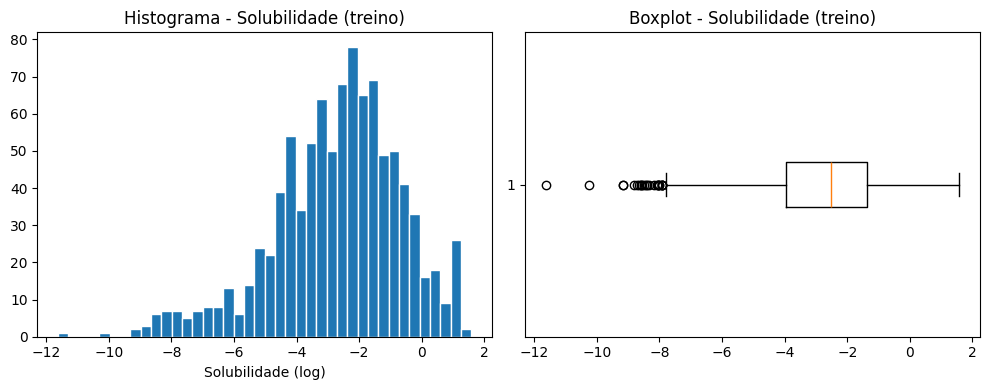

In [3]:
print(y_treino.describe().round(3).to_string())
print('assimetria:', round(y_treino.skew(), 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(y_treino, bins=40, edgecolor='white')
axes[0].set_title('Histograma - Solubilidade (treino)')
axes[0].set_xlabel('Solubilidade (log)')
axes[1].boxplot(y_treino, vert=False)
axes[1].set_title('Boxplot - Solubilidade (treino)')
plt.tight_layout()
salvar_figura('hist_solubilidade')
plt.show()

A solubilidade vai de cerca de -11,6 a 1,6, com média -2,7. A distribuição é razoavelmente simétrica
(assimetria por volta de -0,67), com uma cauda à esquerda formada por poucos compostos muito
insolúveis. Não vemos necessidade de transformar a saída.

## Assimetria dos preditores

Os 208 preditores binários não são transformados: uma variável 0/1 tem só dois valores, e qualquer
transformação monotônica apenas troca o rótulo dos dois níveis, sem mudar a forma da distribuição. A
assimetria deles reflete só a frequência da subestrutura (a maioria aparece em poucos compostos).

O foco então são os 20 preditores não binários. Abaixo os histogramas e a assimetria de cada um na
escala original.

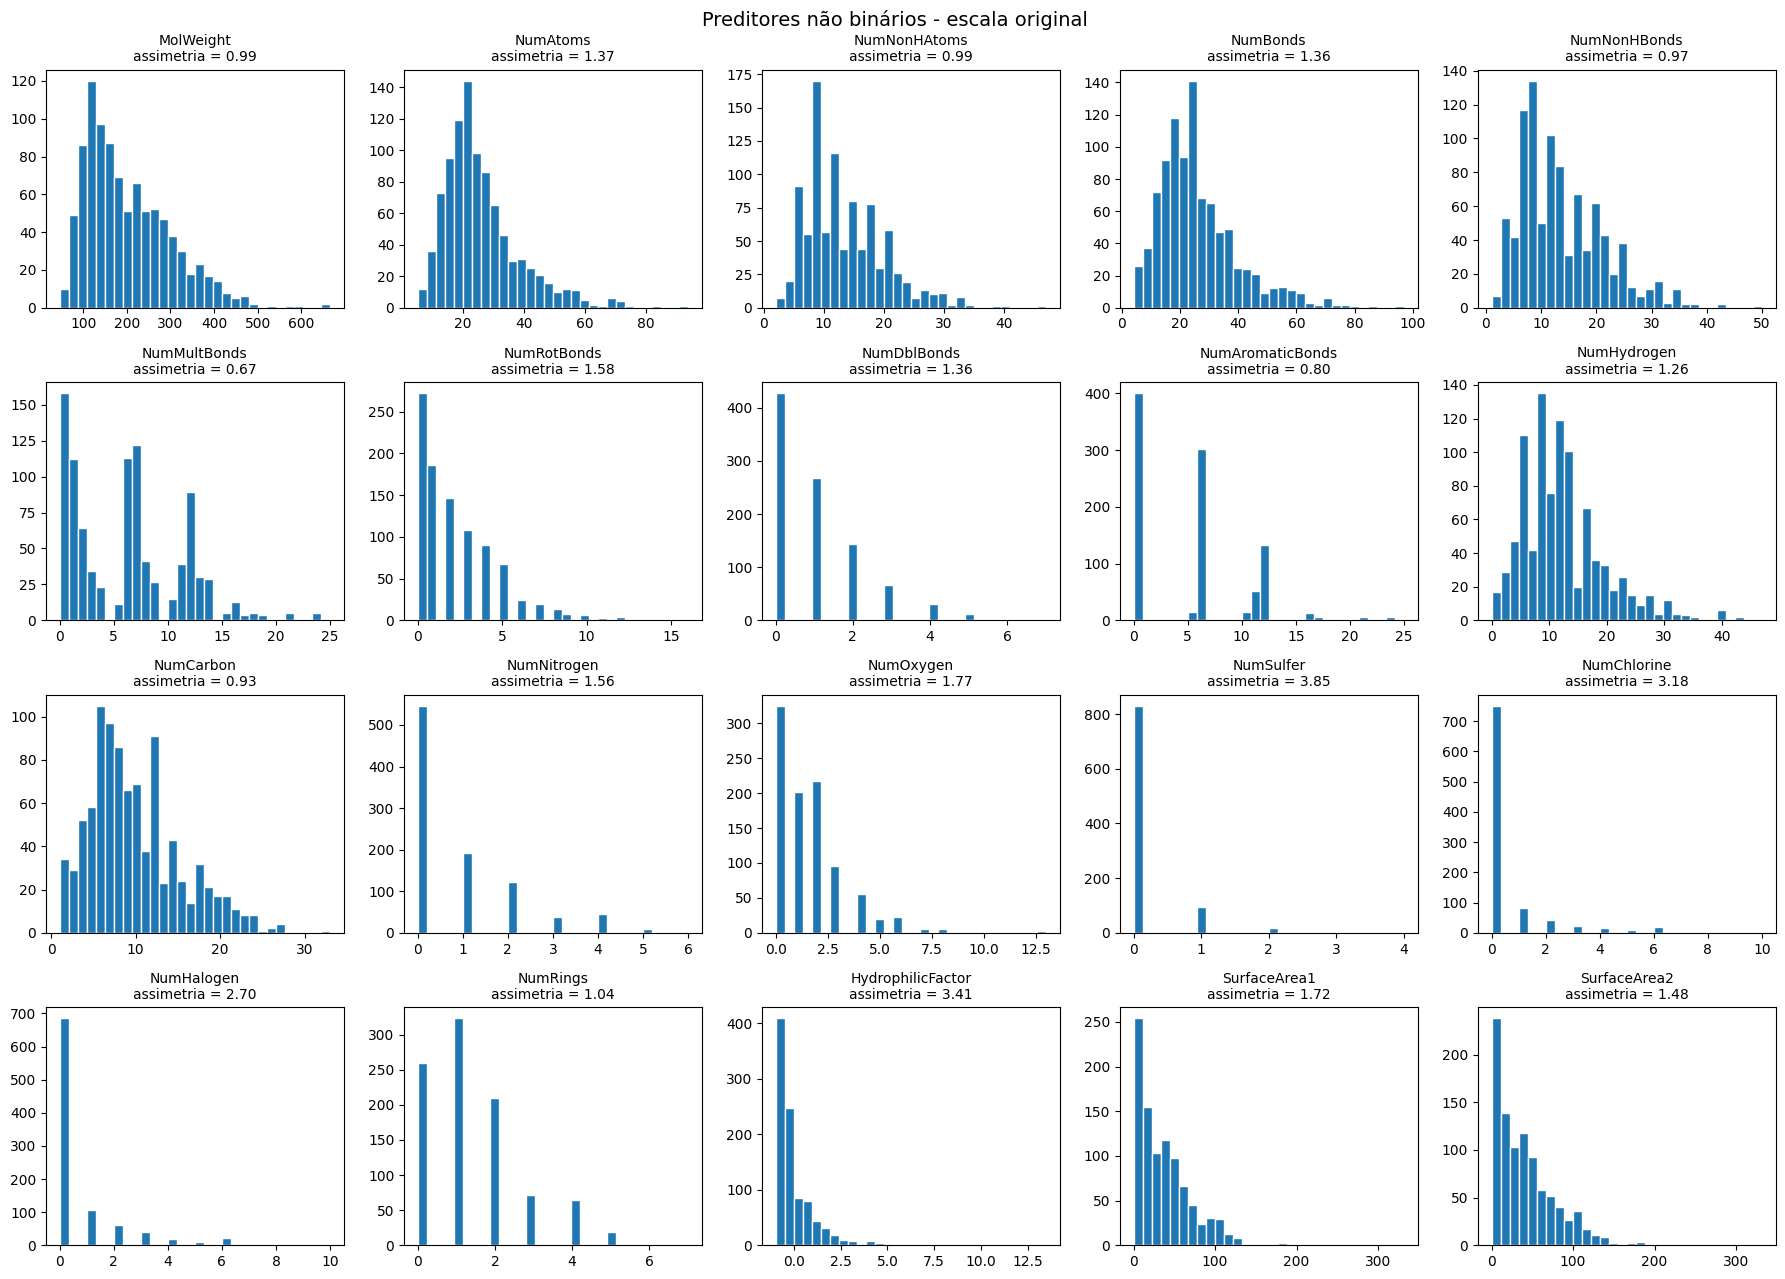

Frequencia media dos FP (fracao de compostos com a subestrutura): 0.194
Assimetria dos FP: mediana = 2.19, max = 4.85


In [4]:
def grade_histogramas(dados, colunas, titulo, nome_figura):
    fig, axes = plt.subplots(4, 5, figsize=(18, 13))
    for ax, coluna in zip(axes.ravel(), colunas):
        ax.hist(dados[coluna], bins=30, edgecolor='white')
        ax.set_title('%s\nassimetria = %.2f' % (coluna, dados[coluna].skew()), fontsize=10)
    fig.suptitle(titulo, fontsize=14)
    plt.tight_layout()
    salvar_figura(nome_figura)
    plt.show()
    return

grade_histogramas(X_treino, nao_binarios, 'Preditores não binários - escala original', 'hist_originais')

print('Frequencia media dos FP (fracao de compostos com a subestrutura): %.3f' % X_treino[binarios].mean().mean())
print('Assimetria dos FP: mediana = %.2f, max = %.2f' % (X_treino[binarios].skew().median(), X_treino[binarios].skew().max()))

Todos os 20 preditores não binários têm assimetria positiva, isto é, cauda longa à direita. É o
esperado para contagens e tamanhos moleculares: a maioria dos compostos é pequena e alguns poucos são
bem maiores. Os casos mais extremos são `NumSulfer`, `HydrophilicFactor`, `NumChlorine` e
`NumHalogen`, todos com assimetria acima de 2,5.

### Transformação de Yeo-Johnson

A transformação clássica para remover assimetria é a de Box-Cox, mas ela só aceita valores
estritamente positivos. Aqui isso não serve: quase todas as contagens têm zeros (um composto pode não
ter nenhum átomo de enxofre) e o `HydrophilicFactor` tem valores negativos. Usamos então a
transformação de **Yeo-Johnson**, que é a extensão da Box-Cox para a reta real inteira:

$$
\psi(x, \lambda) =
\begin{cases}
\dfrac{(x+1)^\lambda - 1}{\lambda}, & x \ge 0,\ \lambda \ne 0 \\
\ln(x+1), & x \ge 0,\ \lambda = 0 \\
-\dfrac{(1-x)^{2-\lambda} - 1}{2-\lambda}, & x < 0,\ \lambda \ne 2 \\
-\ln(1-x), & x < 0,\ \lambda = 2
\end{cases}
$$

Para cada preditor, o parâmetro $\lambda$ é estimado por máxima verossimilhança no conjunto de treino
(`scipy.stats.yeojohnson`). O mesmo $\lambda$ é depois aplicado ao conjunto de teste, para que o teste
não influencie em nada o pré-processamento.

In [5]:
X_treino_t = X_treino.copy()
X_teste_t = X_teste.copy()
lambdas = {}

for coluna in nao_binarios:
    X_treino_t[coluna], lambdas[coluna] = stats.yeojohnson(X_treino[coluna].astype(float))  # estima lambda no treino
    X_teste_t[coluna] = stats.yeojohnson(X_teste[coluna].astype(float), lmbda=lambdas[coluna])  # reaplica no teste

tabela_assimetria = pd.DataFrame({
    'lambda': pd.Series(lambdas),
    'assimetria_original': X_treino[nao_binarios].skew(),
    'assimetria_transformada': X_treino_t[nao_binarios].skew(),
}).round(3)

print(tabela_assimetria.to_string())

                   lambda  assimetria_original  assimetria_transformada
MolWeight           0.000                0.990                   -0.000
NumAtoms            0.048                1.367                    0.001
NumNonHAtoms        0.051                0.995                   -0.004
NumBonds            0.113                1.362                    0.005
NumNonHBonds        0.152                0.971                   -0.013
NumMultBonds        0.358                0.671                   -0.142
NumRotBonds        -0.078                1.580                    0.021
NumDblBonds        -0.577                1.362                    0.159
NumAromaticBonds    0.133                0.797                   -0.085
NumHydrogen         0.332                1.264                    0.029
NumCarbon           0.253                0.929                   -0.004
NumNitrogen        -1.284                1.557                    0.430
NumOxygen          -0.171                1.774                  

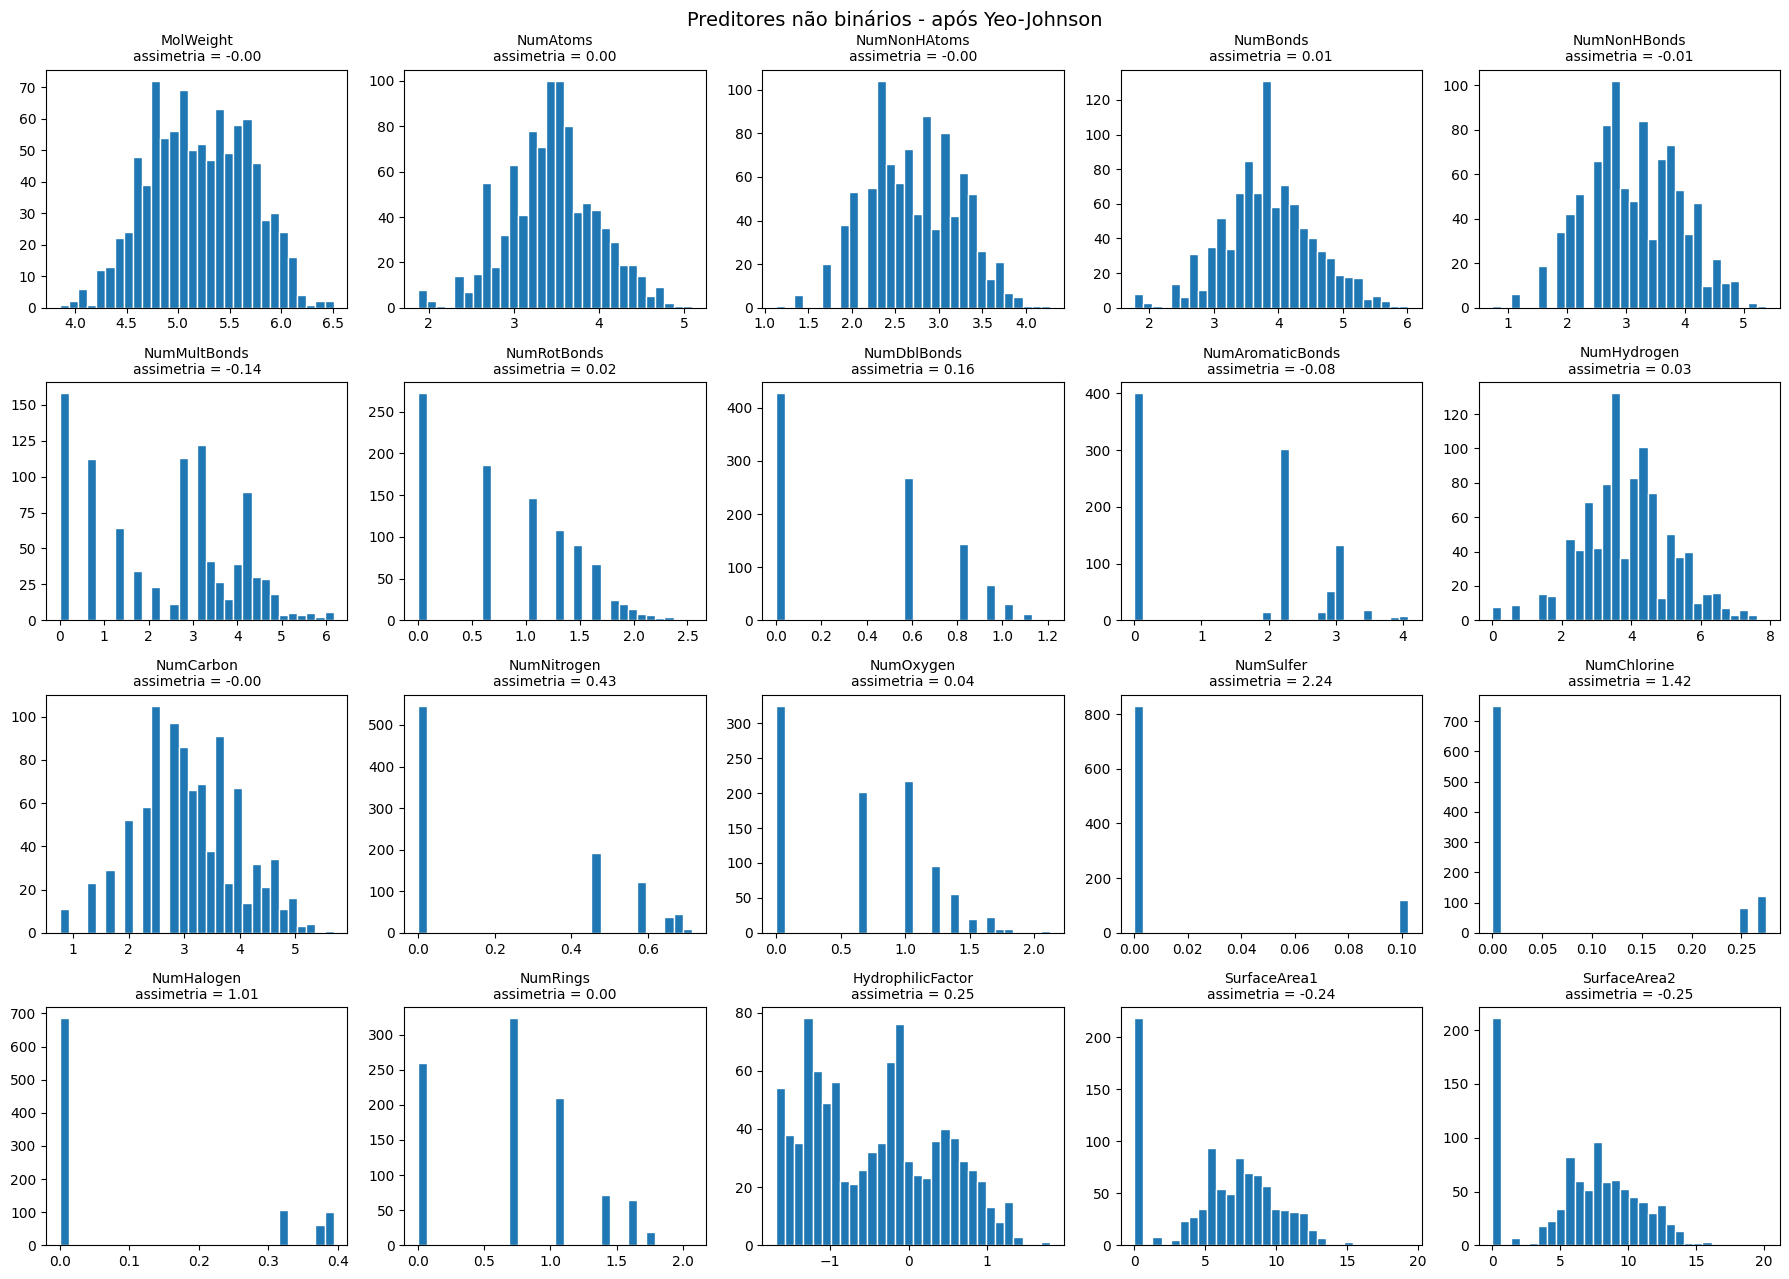

In [6]:
grade_histogramas(X_treino_t, nao_binarios, 'Preditores não binários - após Yeo-Johnson', 'hist_transformados')

A transformação resolveu a assimetria de 16 dos 20 preditores, que agora ficam com assimetria entre
-0,25 e 0,25. Vários $\lambda$ ficaram perto de zero (`MolWeight`, `NumAtoms`, `NumNonHAtoms`,
`NumRings`), o que equivale a um $\ln(x+1)$: para tamanhos moleculares a escala logarítmica é a natural.

Os que continuam assimétricos são `NumSulfer` (2,24), `NumChlorine` (1,42), `NumHalogen` (1,01) e, em
menor grau, `NumNitrogen` (0,43). Isso não é falha da transformação. Esses preditores são dominados
por zeros (a grande maioria dos compostos não tem enxofre nem cloro), e a distribuição fica parecida
com a de uma variável quase binária: um pico enorme em 0 e poucos valores espalhados acima. Uma
transformação monotônica não consegue "espalhar" um ponto único com centenas de observações, então
sempre sobra uma assimetria residual. Os $\lambda$ muito negativos dessas colunas (até -9,8 em
`NumSulfer`) são o otimizador tentando comprimir a cauda o máximo possível.

Como checagem, os arquivos `solTrainXtrans.txt`/`solTestXtrans.txt` que vêm junto com o dataset trazem
uma versão já transformada (Box-Cox, feita no pacote `caret` do R). Comparamos a assimetria dela com a nossa.

In [7]:
X_treino_ref = ler('solTrainXtrans.txt')

comparacao = pd.DataFrame({
    'nossa (Yeo-Johnson)': X_treino_t[nao_binarios].skew(),
    'fornecida (Box-Cox)': X_treino_ref[nao_binarios].skew(),
    'correlacao entre as duas': [np.corrcoef(X_treino_t[c], X_treino_ref[c])[0, 1] for c in nao_binarios],
}).round(3)
print(comparacao.to_string())

                   nossa (Yeo-Johnson)  fornecida (Box-Cox)  correlacao entre as duas
MolWeight                       -0.000               -0.000                     1.000
NumAtoms                         0.001               -0.072                     1.000
NumNonHAtoms                    -0.004               -0.056                     1.000
NumBonds                         0.005               -0.189                     0.999
NumNonHBonds                    -0.013                0.043                     1.000
NumMultBonds                    -0.142               -0.095                     1.000
NumRotBonds                      0.021                0.098                     1.000
NumDblBonds                      0.159                0.150                     1.000
NumAromaticBonds                -0.085               -0.147                     0.999
NumHydrogen                      0.029               -0.041                     1.000
NumCarbon                       -0.004                

As duas versões são praticamente equivalentes (correlação muito alta coluna a coluna) e deixam as mesmas
colunas com assimetria residual, o que confirma o diagnóstico acima. A partir daqui toda a análise usa
os nossos preditores transformados (`X_treino_t`).

## Relações entre pares de preditores

Estimamos a matriz de correlação de Pearson entre os 228 preditores transformados. Ela tem
228 x 227 / 2 = 25.878 pares distintos, então primeiro olhamos a matriz inteira como imagem e um
resumo de quantos pares têm correlação alta.

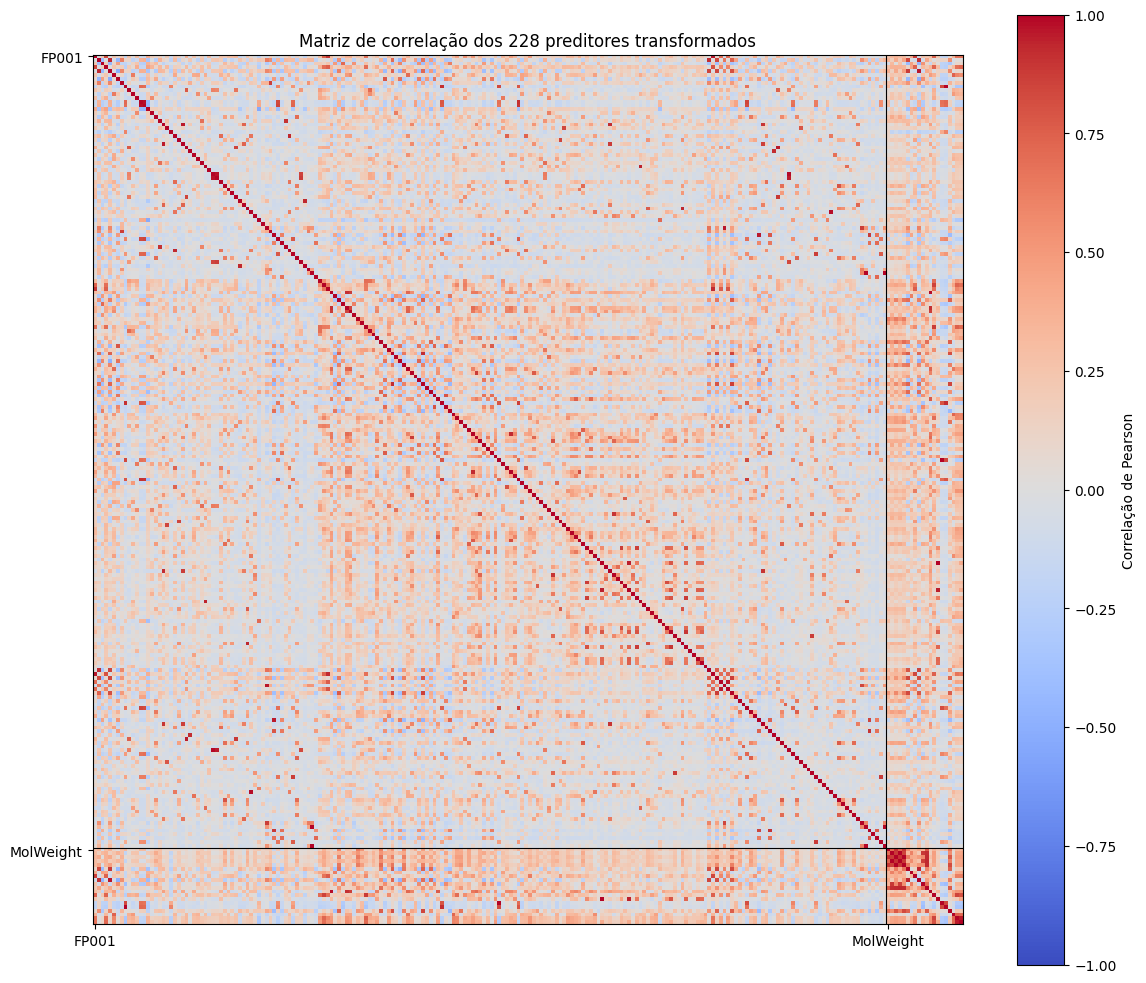

Numero de pares distintos: 25878
  pares com |r| > 0.50:  881
  pares com |r| > 0.75:  176
  pares com |r| > 0.90:   47
  pares com |r| > 0.95:   24


In [8]:
correlacao = X_treino_t.corr()

fig, ax = plt.subplots(figsize=(12, 10))
imagem = ax.imshow(correlacao, cmap='coolwarm', vmin=-1, vmax=1)
ax.axhline(len(binarios) - 0.5, color='black', lw=0.8)  # separa FP dos nao binarios
ax.axvline(len(binarios) - 0.5, color='black', lw=0.8)
ax.set_xticks([0, len(binarios)])
ax.set_xticklabels(['FP001', nao_binarios[0]])
ax.set_yticks([0, len(binarios)])
ax.set_yticklabels(['FP001', nao_binarios[0]])
fig.colorbar(imagem, ax=ax, label='Correlação de Pearson')
ax.set_title('Matriz de correlação dos 228 preditores transformados')
plt.tight_layout()
salvar_figura('matriz_correlacao_completa')
plt.show()

triangulo = np.triu(np.ones(correlacao.shape, dtype=bool), k=1)  # so os pares distintos (acima da diagonal)
pares = correlacao.where(triangulo).stack().dropna()
pares = pares.reindex(pares.abs().sort_values(ascending=False).index)

print('Numero de pares distintos:', len(pares))
for limiar in [0.5, 0.75, 0.9, 0.95]:
    print('  pares com |r| > %.2f: %4d' % (limiar, (pares.abs() > limiar).sum()))

Os 30 pares mais correlacionados:

In [9]:
print(pares.head(30).round(3).to_string())

FP134         NumSulfer           1.000
FP107         NumChlorine         0.999
NumAtoms      NumBonds            0.997
FP009         NumHalogen          0.996
FP058         FP203               0.995
              FP208               0.995
NumNonHAtoms  NumNonHBonds        0.995
FP203         FP208               0.990
FP032         FP183               0.985
FP013         FP014               0.981
FP042         FP194               0.981
FP063         NumNitrogen         0.978
FP032         FP033               0.969
FP046         FP166               0.965
FP001         FP163               0.963
FP005         NumAromaticBonds    0.962
SurfaceArea1  SurfaceArea2        0.960
FP025         FP180               0.958
FP019         FP024               0.955
FP048         FP175               0.954
FP033         FP183               0.954
FP165         FP167               0.954
FP141         NumSulfer           0.952
FP134         FP141               0.952
FP030         FP144               0.943


E o detalhe da matriz só para os 20 preditores não binários, onde dá para ler os valores:

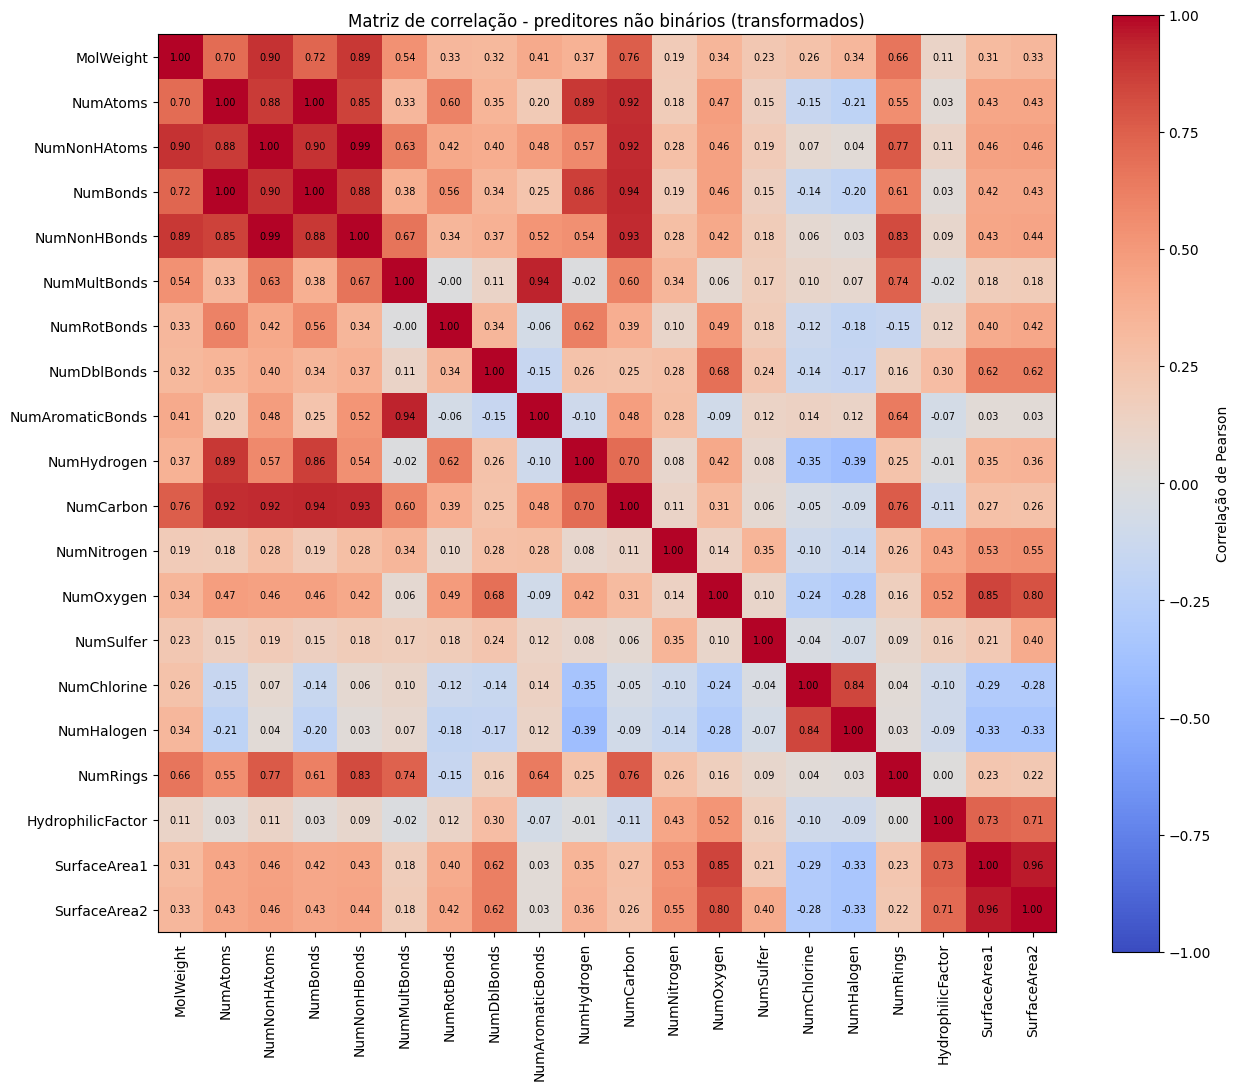

In [10]:
corr_nb = correlacao.loc[nao_binarios, nao_binarios]

fig, ax = plt.subplots(figsize=(13, 11))
imagem = ax.imshow(corr_nb, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(nao_binarios)))
ax.set_yticks(range(len(nao_binarios)))
ax.set_xticklabels(nao_binarios, rotation=90)
ax.set_yticklabels(nao_binarios)
for i in range(len(nao_binarios)):
    for j in range(len(nao_binarios)):
        ax.text(j, i, '%.2f' % corr_nb.iloc[i, j], ha='center', va='center', fontsize=7)
fig.colorbar(imagem, ax=ax, label='Correlação de Pearson')
ax.set_title('Matriz de correlação - preditores não binários (transformados)')
plt.tight_layout()
salvar_figura('matriz_correlacao_nao_binarios')
plt.show()

**Comentários sobre as relações entre preditores.**

A maior parte dos pares é fracamente correlacionada (a matriz completa é majoritariamente branca), mas
existe um grupo considerável de relações fortes: 47 pares com |r| > 0,9 e 176 com |r| > 0,75. Elas
aparecem em três situações:

1. **Preditores que medem praticamente a mesma coisa.** `NumAtoms` e `NumBonds` (r = 0,997),
   `NumNonHAtoms` e `NumNonHBonds` (0,995), `SurfaceArea1` e `SurfaceArea2` (0,96). Numa molécula, o
   número de ligações acompanha o número de átomos quase exatamente, e as duas áreas superficiais só
   diferem em alguns tipos de átomo.
2. **Fingerprint redundante com uma contagem.** `FP134` e `NumSulfer` têm correlação 1,0, `FP107` e
   `NumChlorine` 0,999, `FP009` e `NumHalogen` 0,996, `FP063` e `NumNitrogen` 0,98, `FP005` e
   `NumAromaticBonds` 0,96. Como essas contagens são quase sempre 0 ou 1, elas carregam a mesma
   informação que o fingerprint de "presença" do respectivo átomo.
3. **Fingerprints redundantes entre si.** Por exemplo `FP058`, `FP203` e `FP208` (r ≈ 0,99 entre os
   três), `FP032`/`FP183`/`FP033`, `FP013`/`FP014`. Provavelmente são subestruturas aninhadas, em que uma
   praticamente só aparece quando a outra aparece.

Entre os não binários dá para enxergar dois blocos. Um bloco de **tamanho da molécula** (`MolWeight`,
`NumAtoms`, `NumNonHAtoms`, `NumBonds`, `NumNonHBonds`, `NumCarbon`, `NumRings`), com correlações de
0,7 a 1,0 entre si; e um bloco de **polaridade** (`NumOxygen`, `NumDblBonds`, `HydrophilicFactor`,
`SurfaceArea1`, `SurfaceArea2`), com correlações entre 0,5 e 0,85. `NumMultBonds` e
`NumAromaticBonds` também andam juntos (0,94). Os halogênios (`NumChlorine`, `NumHalogen`) têm leve
correlação negativa com `NumHydrogen` (-0,35 a -0,39), já que onde há um halogênio ligado ao carbono não
há hidrogênio.

A consequência prática é que há **forte multicolinearidade** no conjunto: muitos preditores são
combinações quase lineares de outros. Isso deixa instáveis os coeficientes de uma regressão linear por
mínimos quadrados e indica que métodos com regularização (ridge, lasso) ou com redução de dimensão
(PCR, PLS), ou ainda a remoção dos preditores redundantes, tendem a funcionar melhor nesse problema.

## Relação entre cada preditor e a saída

Agora calculamos a correlação de cada um dos 228 preditores transformados com a solubilidade. Além
da correlação de Pearson, que mede só relação **linear**, calculamos a de Spearman, que mede relação
**monotônica** qualquer (é a Pearson calculada sobre os postos). Se as duas forem parecidas, a relação
é aproximadamente linear; se a Spearman for bem maior em módulo, há uma relação monotônica mas curva.
Para os binários, a correlação de Pearson é exatamente a correlação ponto-bisserial, que é o que
interessa nesse caso.

In [11]:
correlacao_saida = pd.DataFrame({
    'pearson': X_treino_t.corrwith(y_treino),
    'spearman': X_treino_t.corrwith(y_treino, method='spearman'),
    'pearson_escala_original': X_treino.corrwith(y_treino),
})

print('===== Preditores nao binarios (ordenados pela Pearson) =====')
print(correlacao_saida.loc[nao_binarios].sort_values('pearson').round(3).to_string())

print('\n===== Resumo de |r| =====')
for nome, colunas in [('nao binarios', nao_binarios), ('binarios', binarios)]:
    r = correlacao_saida.loc[colunas, 'pearson'].abs()
    print('%-13s |r| medio = %.3f   |r| max = %.3f   |r|>0.3: %3d   |r|>0.5: %2d'
          % (nome, r.mean(), r.max(), (r > 0.3).sum(), (r > 0.5).sum()))

===== Preditores nao binarios (ordenados pela Pearson) =====
                   pearson  spearman  pearson_escala_original
MolWeight           -0.659    -0.685                   -0.629
NumCarbon           -0.607    -0.674                   -0.583
NumNonHBonds        -0.585    -0.632                   -0.551
NumNonHAtoms        -0.583    -0.630                   -0.545
NumRings            -0.481    -0.509                   -0.488
NumMultBonds        -0.476    -0.480                   -0.525
NumBonds            -0.459    -0.548                   -0.420
NumAtoms            -0.436    -0.520                   -0.399
NumAromaticBonds    -0.425    -0.458                   -0.516
NumHalogen          -0.387    -0.381                   -0.504
NumChlorine         -0.377    -0.357                   -0.504
NumHydrogen         -0.154    -0.256                   -0.204
NumRotBonds         -0.112    -0.150                   -0.149
NumSulfer           -0.073    -0.121                   -0.091
NumDblBon

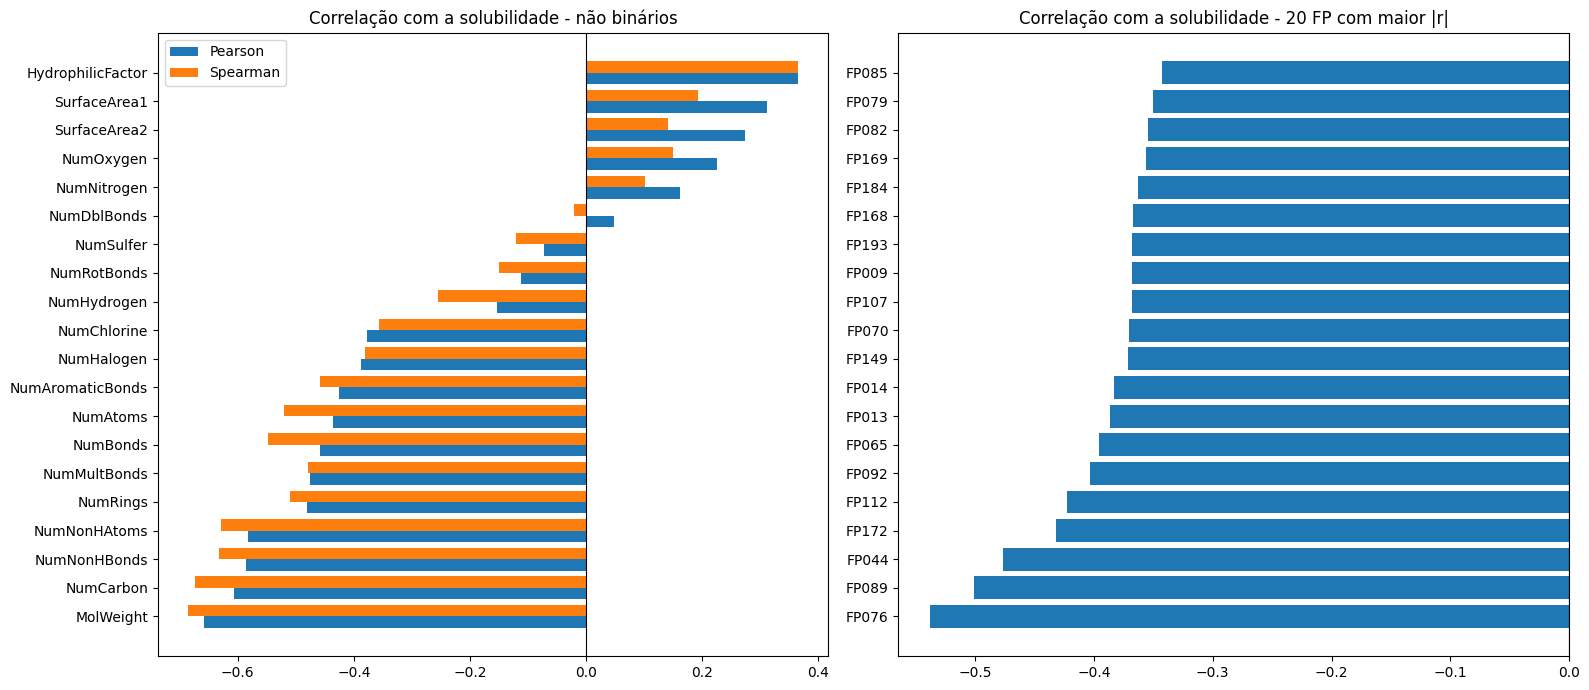

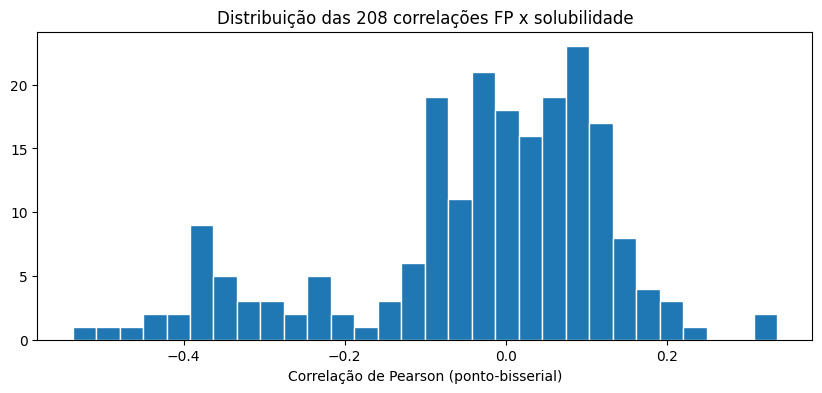

In [12]:
ordem = correlacao_saida['pearson'].sort_values()
top_fp = correlacao_saida.loc[binarios, 'pearson'].abs().sort_values(ascending=False).index[:20]

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
dados_nb = correlacao_saida.loc[nao_binarios].sort_values('pearson')
posicoes = np.arange(len(dados_nb))
axes[0].barh(posicoes - 0.2, dados_nb['pearson'], height=0.4, label='Pearson')
axes[0].barh(posicoes + 0.2, dados_nb['spearman'], height=0.4, label='Spearman')
axes[0].set_yticks(posicoes)
axes[0].set_yticklabels(dados_nb.index)
axes[0].axvline(0, color='black', lw=0.8)
axes[0].set_title('Correlação com a solubilidade - não binários')
axes[0].legend()

dados_fp = correlacao_saida.loc[top_fp].sort_values('pearson')
axes[1].barh(range(len(dados_fp)), dados_fp['pearson'])
axes[1].set_yticks(range(len(dados_fp)))
axes[1].set_yticklabels(dados_fp.index)
axes[1].axvline(0, color='black', lw=0.8)
axes[1].set_title('Correlação com a solubilidade - 20 FP com maior |r|')
plt.tight_layout()
salvar_figura('correlacao_preditor_saida')
plt.show()

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(correlacao_saida.loc[binarios, 'pearson'], bins=30, edgecolor='white')
ax.set_title('Distribuição das 208 correlações FP x solubilidade')
ax.set_xlabel('Correlação de Pearson (ponto-bisserial)')
salvar_figura('hist_correlacao_fp_saida')
plt.show()

A correlação só mede a força da tendência linear; para ver a **forma** da relação, plotamos a
solubilidade contra cada preditor não binário transformado. Em cada painel desenhamos a reta de mínimos
quadrados (vermelho) e um ajuste quadrático (verde). Se a curva verde se afasta da reta, a relação tem
curvatura.

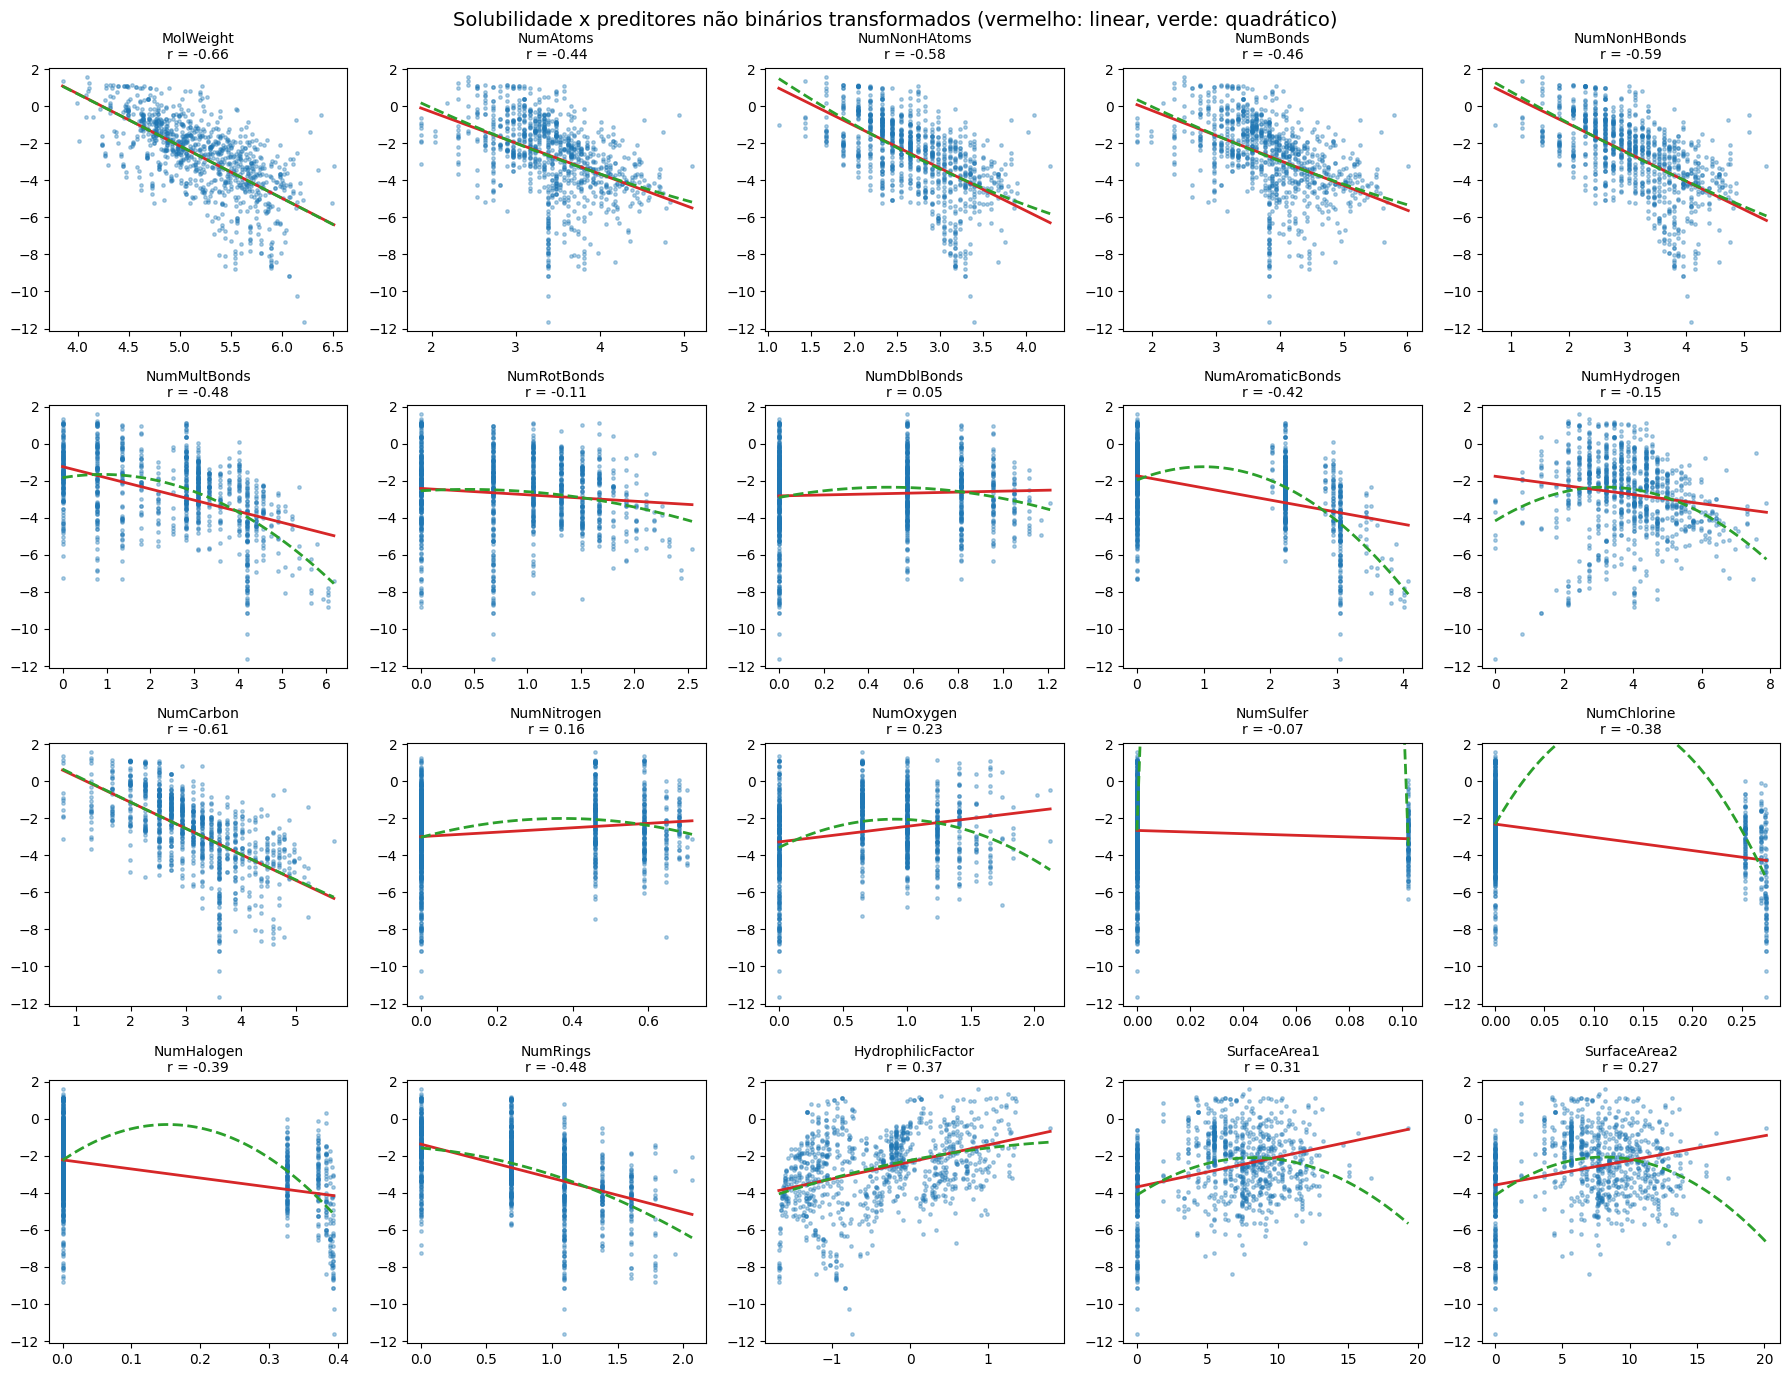

                   R2_linear  R2_quadratico  ganho_quadratico
NumAromaticBonds       0.181          0.310             0.129
SurfaceArea2           0.075          0.161             0.085
NumMultBonds           0.227          0.289             0.062
NumOxygen              0.051          0.111             0.060
SurfaceArea1           0.097          0.154             0.057
NumHydrogen            0.024          0.072             0.049
NumChlorine            0.142          0.189             0.047
NumHalogen             0.150          0.193             0.043
NumRings               0.231          0.246             0.015
NumDblBonds            0.002          0.015             0.013
NumNitrogen            0.026          0.038             0.012
NumRotBonds            0.013          0.019             0.006
HydrophilicFactor      0.133          0.136             0.002
NumNonHAtoms           0.340          0.341             0.001
NumSulfer              0.005          0.006             0.001
NumAtoms

In [13]:
fig, axes = plt.subplots(4, 5, figsize=(18, 14))
r2_linear, r2_quadratico = {}, {}
variancia_y = np.var(y_treino)

for ax, coluna in zip(axes.ravel(), nao_binarios):
    x = X_treino_t[coluna].values
    grade = np.linspace(x.min(), x.max(), 100)
    coef1 = np.polyfit(x, y_treino, 1)
    coef2 = np.polyfit(x, y_treino, 2)
    r2_linear[coluna] = 1 - np.var(y_treino - np.polyval(coef1, x)) / variancia_y
    r2_quadratico[coluna] = 1 - np.var(y_treino - np.polyval(coef2, x)) / variancia_y

    ax.scatter(x, y_treino, s=6, alpha=0.35)
    ax.plot(grade, np.polyval(coef1, grade), color='tab:red', lw=2)
    ax.plot(grade, np.polyval(coef2, grade), color='tab:green', lw=2, ls='--')
    ax.set_ylim(y_treino.min() - 0.5, y_treino.max() + 0.5)  # mesma escala da saida em todos os paineis
    ax.set_title('%s\nr = %.2f' % (coluna, correlacao_saida.loc[coluna, 'pearson']), fontsize=10)

fig.suptitle('Solubilidade x preditores não binários transformados (vermelho: linear, verde: quadrático)', fontsize=14)
plt.tight_layout()
salvar_figura('scatter_preditores_saida')
plt.show()

tabela_r2 = pd.DataFrame({'R2_linear': r2_linear, 'R2_quadratico': r2_quadratico})
tabela_r2['ganho_quadratico'] = tabela_r2['R2_quadratico'] - tabela_r2['R2_linear']
print(tabela_r2.sort_values('ganho_quadratico', ascending=False).round(3).to_string())

Para os binários, o gráfico equivalente é o boxplot da solubilidade nos dois grupos (subestrutura
ausente x presente). Mostramos os 8 fingerprints com maior |r|.

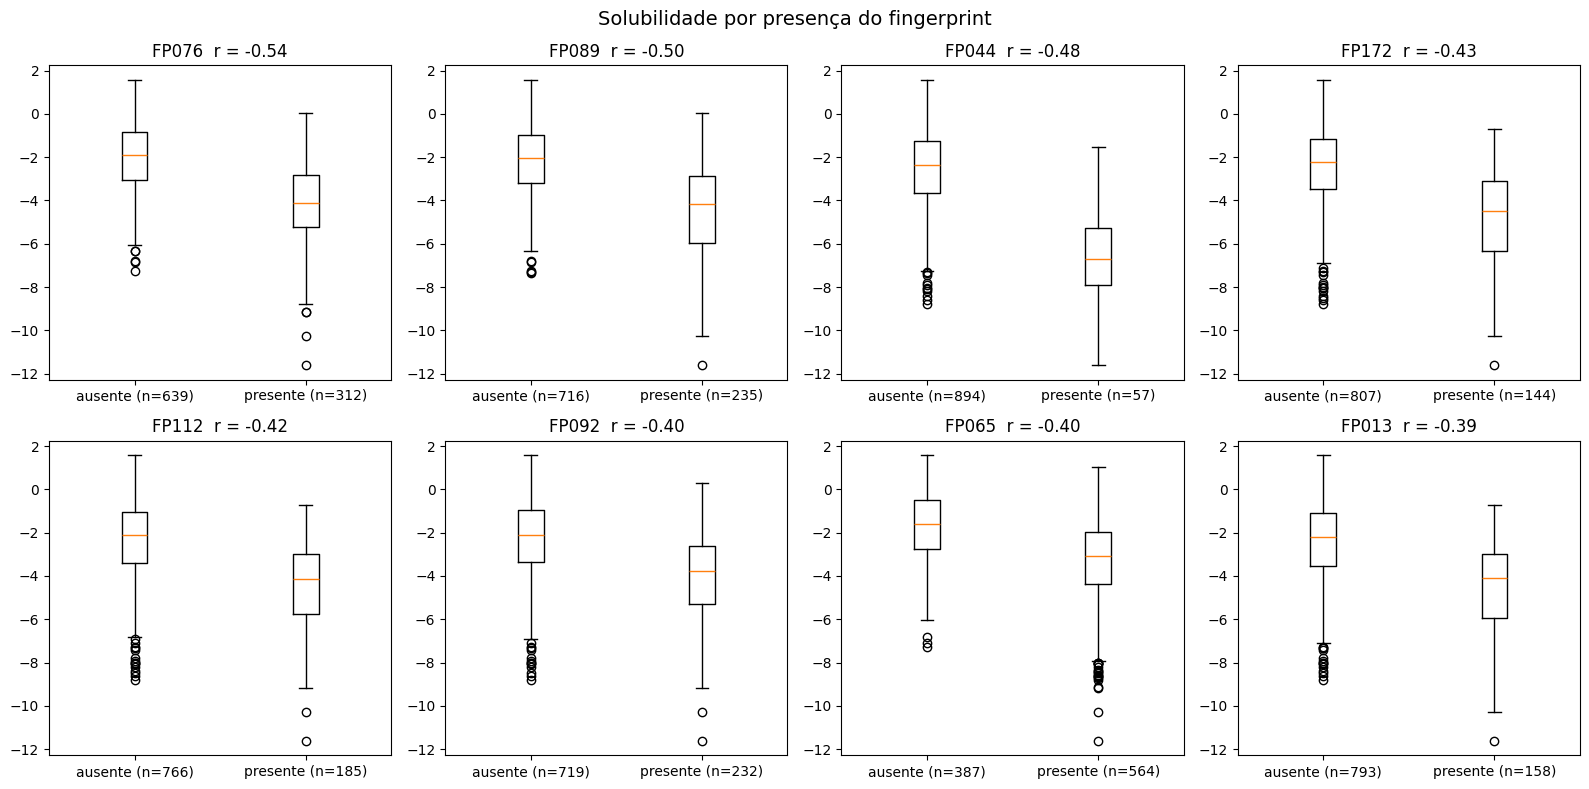

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, coluna in zip(axes.ravel(), top_fp[:8]):
    grupos = [y_treino[X_treino_t[coluna] == 0], y_treino[X_treino_t[coluna] == 1]]
    ax.boxplot(grupos)
    ax.set_xticks([1, 2])
    ax.set_xticklabels(['ausente (n=%d)' % len(grupos[0]), 'presente (n=%d)' % len(grupos[1])])
    ax.set_title('%s  r = %.2f' % (coluna, correlacao_saida.loc[coluna, 'pearson']))
fig.suptitle('Solubilidade por presença do fingerprint', fontsize=14)
plt.tight_layout()
salvar_figura('boxplot_fp_saida')
plt.show()

**Comentários sobre as relações preditor x saída.**

*Preditores não binários.* As relações mais fortes são todas **negativas** e vêm do bloco de tamanho
molecular: `MolWeight` (r = -0,66), `NumCarbon` (-0,61), `NumNonHBonds` e `NumNonHAtoms` (-0,58),
seguidos de `NumRings`, `NumMultBonds`, `NumBonds`, `NumAtoms`, `NumAromaticBonds` e dos halogênios
(entre -0,38 e -0,48). Faz sentido químico: moléculas maiores, mais aromáticas e com halogênios são mais
hidrofóbicas e se dissolvem menos em água. Do outro lado, os preditores de polaridade têm correlação
**positiva** com a solubilidade, mas fraca: `HydrophilicFactor` (0,37), `SurfaceArea1` (0,31),
`SurfaceArea2` (0,27) e `NumOxygen` (0,23). `NumDblBonds`, `NumSulfer`, `NumRotBonds` e `NumHydrogen`
praticamente não têm relação individual com a saída (|r| < 0,16). Nenhum preditor sozinho explica mais
que cerca de 43% da variância da solubilidade (r² de `MolWeight`).

*São relações lineares?* Para os preditores mais importantes, sim, aproximadamente. Nos preditores de
tamanho (`MolWeight`, `NumCarbon`, `NumNonHAtoms`, `NumNonHBonds`, `NumAtoms`, `NumBonds`) o ajuste
quadrático coincide com a reta e o ganho de R² é zero, ou seja, depois da transformação a relação é
linear. A transformação ajudou nesses casos: a |r| de `MolWeight` passou de 0,63 na escala original
para 0,66, a de `NumNonHAtoms` de 0,55 para 0,58 e a de `NumAtoms` de 0,40 para 0,44. Em outros ela
piorou a correlação linear: `NumMultBonds` (0,53 para 0,48), `NumAromaticBonds` (0,52 para 0,43) e os
halogênios (0,50 para 0,38). Remover a assimetria não garante uma relação mais linear com a saída; nesses
preditores a relação já era mais linear na escala original.

Há, porém, preditores com **curvatura clara**, onde a quadrática melhora o ajuste de forma relevante:
`NumAromaticBonds` (R² vai de 0,18 para 0,31), `SurfaceArea2` (0,08 para 0,16), `NumMultBonds`
(0,23 para 0,29), `NumOxygen` e `SurfaceArea1` (cerca de +0,06) e `NumHydrogen` (+0,05).

- Em `NumAromaticBonds` e `NumMultBonds` a solubilidade fica praticamente constante entre 0 e um anel
  aromático (6 ligações) e só cai a partir de dois ou mais anéis: a relação é plana e depois decrescente.
- Em `SurfaceArea1`/`SurfaceArea2` há um grupo de compostos com área zero e solubilidade baixa; a partir
  daí a solubilidade sobe com a área e depois se estabiliza ou cai. A relação não é monotônica, o que
  aparece também no fato de a Pearson (0,31/0,27) ser maior que a Spearman (0,19/0,14).
- Em `NumHydrogen` e `NumOxygen` a solubilidade sobe e depois desce (forma de U invertido).
- Em `NumBonds`, `NumAtoms` e `NumHydrogen` a Spearman é bem maior em módulo que a Pearson, sinal de uma
  relação monotônica mas não exatamente linear.

Um cuidado: em `NumSulfer`, `NumChlorine` e `NumHalogen` o ganho da quadrática (até +0,05) não deve ser
lido como curvatura. Na escala original eles vão de 0 a 4 (enxofre) ou de 0 a 10 (cloro e halogênios),
mas o $\lambda$ muito negativo estimado pela Yeo-Johnson comprime todos os valores maiores ou iguais a 1
em praticamente um único ponto (no `NumSulfer`, por exemplo, 1, 2, 3 e 4 viram todos algo perto de 0,10).
Depois da transformação sobram, na prática, só dois ou três aglomerados de pontos, e a parábola apenas
interpola a média de cada aglomerado; no `NumSulfer` ela é quase indeterminada e sai da escala do gráfico.
Isso também explica por que a correlação desses preditores com a saída caiu após a transformação: a
informação de "quantos" átomos de halogênio existem foi praticamente apagada, e eles passaram a se
comportar como variáveis binárias, iguais aos fingerprints correspondentes (`FP107`, `FP009`, `FP134`).
Para esses três preditores a escala original provavelmente é a mais útil para a modelagem.

*Preditores binários.* A maioria dos fingerprints tem relação fraca com a solubilidade (|r| médio de
0,12, mediana 0,09), mas alguns são bem informativos: `FP076` (-0,54), `FP089` (-0,50), `FP044` (-0,48),
`FP172` (-0,43), `FP112` (-0,42) e, com sinal positivo, `FP072` (0,34) e `FP015` (0,33). Para um
preditor binário a pergunta de linearidade não se aplica no mesmo sentido: com dois níveis, a relação é
sempre exatamente uma reta ligando as duas médias, e a correlação mede só a diferença entre elas.

*Resumo.* Após a transformação, as relações individuais entre preditores e saída são majoritariamente
lineares (especialmente para os preditores mais correlacionados com a solubilidade), mas não todas:
alguns descritores apresentam curvatura e até relação não monotônica. Somado à forte
multicolinearidade observada antes, isso sugere que modelos lineares regularizados devem capturar
boa parte do sinal, enquanto modelos não lineares podem ganhar justamente nesses preditores curvos.

# PREPARAÇÃO COMUM AOS MODELOS

As funções, a divisão em folds e as matrizes padronizadas abaixo são usadas por todos os modelos das
próximas seções. Assim, OLS, ridge e PLS são comparados exatamente nos mesmos folds e com o mesmo
pré-processamento.

## Pré-processamento

Os preditores dos modelos são os transformados do item 0 (Yeo-Johnson nos 20 não binários, binários
intactos), seguidos de **centralização e escalonamento** (média 0, desvio 1).

Todo o pré-processamento é estimado **só nos dados de ajuste** e depois reaplicado, sem reestimar, nos
dados avaliados: os $\lambda$ da Yeo-Johnson, as médias e os desvios. Isso vale em dois níveis:

- na validação cruzada, os parâmetros são estimados nos 9 folds de treino e aplicados no fold de validação;
- no modelo final, são estimados no treino inteiro e aplicados no conjunto de teste.

Assim nenhuma informação da parte avaliada vaza para o ajuste. Se um preditor binário ficar constante
dentro de algum fold, o desvio dele é zero; nesse caso usamos desvio 1, e a coluna escalonada fica toda
nula e não influencia o modelo.


In [15]:
def ajustar_preprocessamento(X):
    """Estima os lambdas da Yeo-Johnson e a media/desvio dos preditores transformados."""
    lambdas = {c: stats.yeojohnson(X[c].astype(float))[1] for c in nao_binarios}
    X_t = aplicar_yeojohnson(X, lambdas)
    medias = X_t.mean().values
    desvios = X_t.std().values.copy()
    desvios[desvios == 0] = 1.0  # coluna constante no fold: evita divisao por zero
    return lambdas, medias, desvios

def aplicar_yeojohnson(X, lambdas):
    X_t = X.astype(float).copy()
    for c in nao_binarios:
        X_t[c] = stats.yeojohnson(X[c].astype(float), lmbda=lambdas[c])
    return X_t

def aplicar_preprocessamento(X, parametros):
    """Aplica os parametros estimados (sem reestimar nada) e devolve a matriz numpy padronizada."""
    lambdas, medias, desvios = parametros
    return (aplicar_yeojohnson(X, lambdas).values - medias) / desvios

In [16]:
def rmse(y, y_previsto):
    return np.sqrt(np.mean((y - y_previsto) ** 2))

def r2(y, y_previsto):
    return 1 - np.sum((y - y_previsto) ** 2) / np.sum((y - np.mean(y)) ** 2)

N_FOLDS = 10

gerador = np.random.default_rng(42)
folds = np.array_split(gerador.permutation(len(y_treino)), N_FOLDS)
y_tr = y_treino.values

parametros_finais = ajustar_preprocessamento(X_treino)
X_treino_pad = aplicar_preprocessamento(X_treino, parametros_finais)
X_teste_pad = aplicar_preprocessamento(X_teste, parametros_finais)  # mesmos parametros do treino

print('Tamanho dos folds:', [len(f) for f in folds])
print('X_treino_pad:', X_treino_pad.shape, '  X_teste_pad:', X_teste_pad.shape)


Tamanho dos folds: [96, 95, 95, 95, 95, 95, 95, 95, 95, 95]
X_treino_pad: (951, 228)   X_teste_pad: (316, 228)


# 2. REGRESSÃO LINEAR MÚLTIPLA (OLS)

Usamos os preditores transformados e padronizados da seção anterior. Com $X$ centrado nos dados de
ajuste e $y_c = y - \bar{y}$, o intercepto é a própria média $\bar{y}$ e os coeficientes são

$$\hat{\beta} = (X^\top X)^{+} X^\top y_c = X^{+} y_c .$$

Implementamos a pseudoinversa diretamente a partir da SVD $X = U S V^\top$: valores singulares abaixo de
$\max(n, p)\,\varepsilon\, s_{\max}$ são descartados e $\hat{\beta} = V S^{+} U^\top y_c$. Trabalhar com $X$,
e não com $X^\top X$, evita elevar o número de condição ao quadrado.

A pseudoinversa é necessária por causa da colinearidade vista no item 0 (por exemplo,
`FP134`/`NumSulfer` com $r = 1{,}000$): quando o posto cai, as equações normais não têm solução única, e a
pseudoinversa devolve a de menor norma.


In [17]:
def ols_ajustar(X, y):
    '''OLS por pseudoinversa via SVD. X ja padronizado. Devolve (beta, media_y, posto, valores singulares).'''
    media_y = y.mean()
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    mantidos = s > max(X.shape) * np.finfo(float).eps * s[0]
    beta = Vt[mantidos].T @ ((U[:, mantidos].T @ (y - media_y)) / s[mantidos])
    return beta, media_y, int(mantidos.sum()), s

def ols_prever(X, beta, media_y):
    return X @ beta + media_y

beta_ols, media_y_ols, posto_ols, valores_singulares = ols_ajustar(X_treino_pad, y_tr)
y_previsto_treino_ols = ols_prever(X_treino_pad, beta_ols, media_y_ols)
y_previsto_teste_ols = ols_prever(X_teste_pad, beta_ols, media_y_ols)  # parametros estimados so no treino

# verificacao: a solucao coincide com a de minimos quadrados do numpy
beta_lstsq = np.linalg.lstsq(X_treino_pad, y_tr - media_y_ols, rcond=None)[0]

print('Posto numerico de X_treino_pad: %d de %d colunas' % (posto_ols, X_treino_pad.shape[1]))
print('Numero de condicao: %.1f' % (valores_singulares[0] / valores_singulares[posto_ols - 1]))
print('Diferenca maxima para np.linalg.lstsq: %.2e' % np.abs(beta_ols - beta_lstsq).max())
print('Maior |coeficiente|: %.2f (%s)' % (np.abs(beta_ols).max(), X_treino.columns[np.abs(beta_ols).argmax()]))

resultados_ols = pd.DataFrame({
    'RMSE': [rmse(y_tr, y_previsto_treino_ols), rmse(y_teste.values, y_previsto_teste_ols)],
    'R2': [r2(y_tr, y_previsto_treino_ols), r2(y_teste.values, y_previsto_teste_ols)],
}, index=['treino (ajuste)', 'teste'])
print()
print(resultados_ols.round(4).to_string())


Posto numerico de X_treino_pad: 228 de 228 colunas
Numero de condicao: 31333.9
Diferenca maxima para np.linalg.lstsq: 5.68e-14
Maior |coeficiente|: 106.14 (NumSulfer)

                  RMSE      R2
treino (ajuste)  0.490  0.9426
teste            0.743  0.8718


**Leitura do ajuste.** No treino completo, $X$ tem posto numérico cheio (228 de 228), com número de
condição de cerca de $3{,}1 \times 10^4$: a matriz é mal condicionada, mas não exatamente singular. A
solução coincide com a de `np.linalg.lstsq` até o erro de arredondamento ($\approx 6 \times 10^{-14}$).

O efeito da colinearidade aparece nos coeficientes: o maior módulo chega a cerca de 106 (`NumSulfer`), um
valor sem interpretação física para preditores padronizados, compensado pelo seu quase duplicado `FP134`.
No teste, o OLS obteve **RMSE ≈ 0,743 e $R^2$ ≈ 0,872**, contra RMSE ≈ 0,490 e $R^2$ ≈ 0,943 no treino. A
distância entre os dois indica sobreajuste: são 228 coeficientes estimados com 951 compostos.


## Comparação com a função pronta (`sklearn`)

Ajustamos `sklearn.linear_model.LinearRegression` nas mesmas matrizes padronizadas e comparamos
coeficientes, intercepto, previsões e métricas de teste com a implementação própria.


In [18]:
from sklearn.linear_model import LinearRegression

modelo_sklearn = LinearRegression().fit(X_treino_pad, y_tr)
y_previsto_teste_sklearn = modelo_sklearn.predict(X_teste_pad)

comparacao_ols = pd.DataFrame({
    'RMSE teste': [rmse(y_teste.values, y_previsto_teste_ols), rmse(y_teste.values, y_previsto_teste_sklearn)],
    'R2 teste': [r2(y_teste.values, y_previsto_teste_ols), r2(y_teste.values, y_previsto_teste_sklearn)],
}, index=['implementacao propria', 'sklearn LinearRegression'])
print(comparacao_ols.round(6).to_string())

print('\nDiferenca maxima nos coeficientes: %.2e' % np.abs(beta_ols - modelo_sklearn.coef_).max())
print('Diferenca no intercepto:           %.2e' % abs(media_y_ols - modelo_sklearn.intercept_))
print('Diferenca maxima nas previsoes:    %.2e' % np.abs(y_previsto_teste_ols - y_previsto_teste_sklearn).max())

coef = pd.Series(beta_ols, index=X_treino.columns)
print('\nCoeficientes do par colinear: NumSulfer = %.2f, FP134 = %.2f' % (coef['NumSulfer'], coef['FP134']))


                          RMSE teste  R2 teste
implementacao propria       0.742978  0.871814
sklearn LinearRegression    0.742978  0.871814

Diferenca maxima nos coeficientes: 1.45e-10
Diferenca no intercepto:           7.99e-15
Diferenca maxima nas previsoes:    5.43e-13

Coeficientes do par colinear: NumSulfer = -106.14, FP134 = 105.95


**Resultado da comparação.** As duas implementações são numericamente equivalentes: RMSE de teste
0,742978 e $R^2$ 0,871814 em ambas, com diferença máxima de $1{,}5 \times 10^{-10}$ nos coeficientes e de
$5{,}4 \times 10^{-13}$ nas previsões. Isso valida a implementação própria.

A compensação dentro do par colinear é direta: `NumSulfer` recebe $-106{,}14$ e `FP134` recebe $+105{,}95$.
Os dois efeitos quase se cancelam, de modo que só a soma é bem determinada pelos dados.


## Validação cruzada 10-fold: implementação própria e função pronta

A validação cruzada usa só o treino e reaproveita os mesmos `folds` definidos na preparação comum. Em cada
fold, o pré-processamento e o modelo são estimados nos outros 9 folds e aplicados ao fold de validação.

Na versão pronta, usamos `cross_validate` com um `Pipeline` (`PowerTransformer` nos não binários,
`StandardScaler` e `LinearRegression`). Sem o `Pipeline`, o pré-processamento seria estimado com todos os
dados antes da divisão e haveria vazamento. A função própria recebe o ajuste e a previsão como
argumentos, para ser reutilizada nos próximos modelos.


In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler

def validacao_cruzada(X, y, folds, ajustar, prever):
    '''k-fold com pre-processamento reestimado nos folds de ajuste. Devolve RMSE e R2 de cada fold.'''
    rmse_folds = np.zeros(len(folds))
    r2_folds = np.zeros(len(folds))
    for k, indices_validacao in enumerate(folds):
        indices_ajuste = np.setdiff1d(np.arange(len(y)), indices_validacao)
        parametros_fold = ajustar_preprocessamento(X.iloc[indices_ajuste])
        X_ajuste = aplicar_preprocessamento(X.iloc[indices_ajuste], parametros_fold)
        X_validacao = aplicar_preprocessamento(X.iloc[indices_validacao], parametros_fold)
        modelo = ajustar(X_ajuste, y[indices_ajuste])
        previsao = prever(X_validacao, modelo)
        rmse_folds[k] = rmse(y[indices_validacao], previsao)
        r2_folds[k] = r2(y[indices_validacao], previsao)
    return rmse_folds, r2_folds

rmse_folds_ols, r2_folds_ols = validacao_cruzada(
    X_treino, y_tr, folds, ols_ajustar, lambda X, modelo: ols_prever(X, modelo[0], modelo[1]))

# postos por fold: mostra onde a pseudoinversa realmente atua
postos_folds = []
for indices_validacao in folds:
    indices_ajuste = np.setdiff1d(np.arange(len(y_tr)), indices_validacao)
    X_ajuste = aplicar_preprocessamento(X_treino.iloc[indices_ajuste], ajustar_preprocessamento(X_treino.iloc[indices_ajuste]))
    postos_folds.append(ols_ajustar(X_ajuste, y_tr[indices_ajuste])[2])

# funcao pronta, nos mesmos folds e com o pre-processamento dentro do Pipeline
divisoes = [(np.setdiff1d(np.arange(len(y_tr)), v), v) for v in folds]
pipeline_ols = Pipeline([
    ('yeo_johnson', ColumnTransformer([('nao_binarios', PowerTransformer(method='yeo-johnson', standardize=False), nao_binarios)],
                                      remainder='passthrough')),
    ('padronizacao', StandardScaler()),
    ('ols', LinearRegression()),
])
cv_sklearn = cross_validate(pipeline_ols, X_treino, y_tr, cv=divisoes, scoring=('neg_root_mean_squared_error', 'r2'))
rmse_folds_sklearn = -cv_sklearn['test_neg_root_mean_squared_error']
r2_folds_sklearn = cv_sklearn['test_r2']

tabela_folds = pd.DataFrame({
    'RMSE proprio': rmse_folds_ols, 'RMSE sklearn': rmse_folds_sklearn,
    'R2 proprio': r2_folds_ols, 'R2 sklearn': r2_folds_sklearn, 'posto': postos_folds,
}, index=pd.Index(range(1, N_FOLDS + 1), name='fold'))
print(tabela_folds.round(4).to_string())

print('\nRMSE CV: proprio = %.4f +- %.4f   sklearn = %.4f'
      % (rmse_folds_ols.mean(), rmse_folds_ols.std(ddof=1) / np.sqrt(N_FOLDS), rmse_folds_sklearn.mean()))
print('R2 CV:   proprio = %.4f +- %.4f   sklearn = %.4f'
      % (r2_folds_ols.mean(), r2_folds_ols.std(ddof=1) / np.sqrt(N_FOLDS), r2_folds_sklearn.mean()))
print('Diferenca maxima por fold: RMSE %.2e, R2 %.2e'
      % (np.abs(rmse_folds_ols - rmse_folds_sklearn).max(), np.abs(r2_folds_ols - r2_folds_sklearn).max()))


      RMSE proprio  RMSE sklearn  R2 proprio  R2 sklearn  posto
fold                                                           
1           0.7726        0.7726      0.8843      0.8843    228
2           0.7151        0.7151      0.9022      0.9022    228
3           0.6108        0.6108      0.8952      0.8952    228
4           0.7776        0.7776      0.8522      0.8522    227
5           0.7120        0.7120      0.8852      0.8852    228
6           0.7088        0.7088      0.8898      0.8898    228
7           0.7689        0.7689      0.8131      0.8131    227
8           0.6596        0.6596      0.9074      0.9074    228
9           0.8528        0.8528      0.7920      0.7920    228
10          0.7004        0.7004      0.8330      0.8330    228

RMSE CV: proprio = 0.7279 +- 0.0215   sklearn = 0.7279
R2 CV:   proprio = 0.8654 +- 0.0128   sklearn = 0.8654
Diferenca maxima por fold: RMSE 1.32e-11, R2 6.44e-12


**Resultado da validação cruzada.** A implementação própria e a função pronta dão o mesmo resultado em
todos os folds: RMSE de CV $0{,}7279 \pm 0{,}0215$ e $R^2$ de CV $0{,}8654 \pm 0{,}0128$ (média $\pm$ erro
padrão), com diferença máxima por fold da ordem de $10^{-11}$. Os dois caminhos têm pré-processamentos
escritos de forma independente, o que reforça a verificação.

O posto cai para 227 nos folds 4 e 7: ao retirar alguns compostos, uma coluna torna-se combinação linear
exata das demais. É nesses casos que a pseudoinversa é indispensável, pois as equações normais deixam de ter
solução única. O RMSE varia de 0,611 a 0,853 entre os folds, uma dispersão relevante para folds de 95 compostos.


## Estimativa de validação cruzada x desempenho no teste

A validação cruzada, calculada só no treino, deveria antecipar o erro em dados novos. Comparamos a média
dos 10 folds, com intervalo de 95% pela distribuição $t$ com 9 graus de liberdade, ao desempenho no
teste, com intervalo de 95% por bootstrap de percentis (5000 reamostras dos 316 compostos de teste).


                 estimativa  IC95% inf  IC95% sup
RMSE CV 10-fold      0.7279     0.6792     0.7765
RMSE teste           0.7430     0.6645     0.8243
R2 CV 10-fold        0.8654     0.8365     0.8944
R2 teste             0.8718     0.8327     0.9027

RMSE teste - RMSE CV: 0.0151 (erro padrao da CV: 0.0215)
Desvio padrao de y: treino = 2.047, teste = 2.078


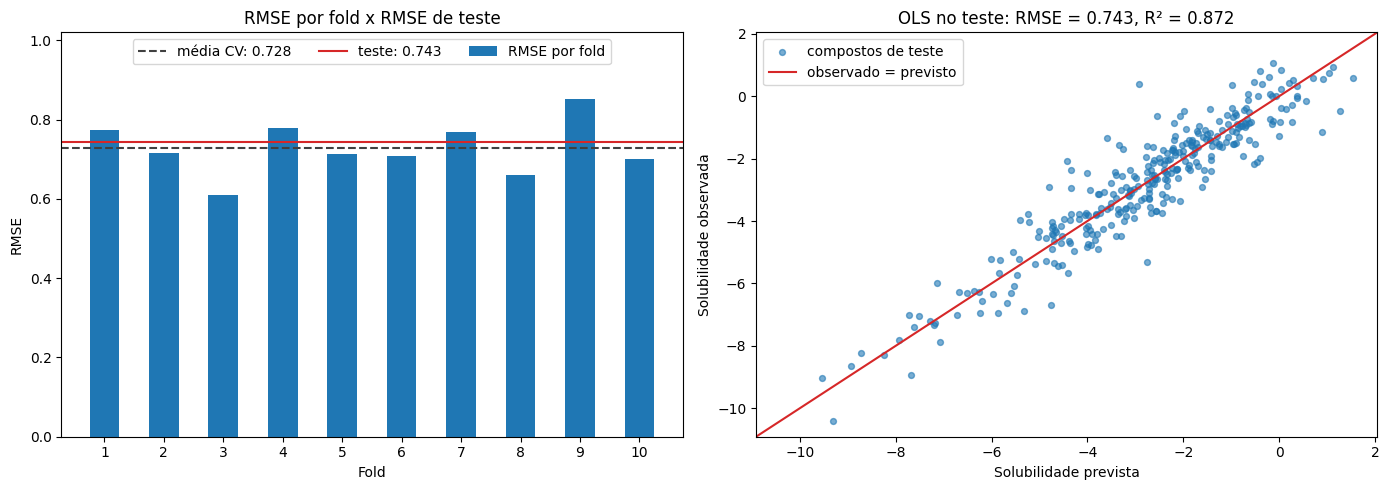

In [20]:
gerador_ols = np.random.default_rng(123)
y_te_ols = y_teste.values
reamostras_ols = np.empty((5000, 2))
for b in range(len(reamostras_ols)):
    amostra = gerador_ols.integers(0, len(y_te_ols), len(y_te_ols))
    reamostras_ols[b] = rmse(y_te_ols[amostra], y_previsto_teste_ols[amostra]), r2(y_te_ols[amostra], y_previsto_teste_ols[amostra])
ic_teste_ols = np.percentile(reamostras_ols, [2.5, 97.5], axis=0)

t_critico = stats.t.ppf(0.975, N_FOLDS - 1)
ep_rmse_ols = rmse_folds_ols.std(ddof=1) / np.sqrt(N_FOLDS)
ep_r2_ols = r2_folds_ols.std(ddof=1) / np.sqrt(N_FOLDS)
rmse_teste_ols = rmse(y_te_ols, y_previsto_teste_ols)
r2_teste_ols = r2(y_te_ols, y_previsto_teste_ols)

resumo_ols = pd.DataFrame({
    'estimativa': [rmse_folds_ols.mean(), rmse_teste_ols, r2_folds_ols.mean(), r2_teste_ols],
    'IC95% inf': [rmse_folds_ols.mean() - t_critico * ep_rmse_ols, ic_teste_ols[0, 0], r2_folds_ols.mean() - t_critico * ep_r2_ols, ic_teste_ols[0, 1]],
    'IC95% sup': [rmse_folds_ols.mean() + t_critico * ep_rmse_ols, ic_teste_ols[1, 0], r2_folds_ols.mean() + t_critico * ep_r2_ols, ic_teste_ols[1, 1]],
}, index=['RMSE CV 10-fold', 'RMSE teste', 'R2 CV 10-fold', 'R2 teste'])
print(resumo_ols.round(4).to_string())
print('\nRMSE teste - RMSE CV: %.4f (erro padrao da CV: %.4f)' % (rmse_teste_ols - rmse_folds_ols.mean(), ep_rmse_ols))
print('Desvio padrao de y: treino = %.3f, teste = %.3f' % (y_tr.std(ddof=1), y_te_ols.std(ddof=1)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, N_FOLDS + 1), rmse_folds_ols, width=0.5, color='tab:blue', label='RMSE por fold')
axes[0].axhline(rmse_folds_ols.mean(), color='0.25', ls='--', label='média CV: %.3f' % rmse_folds_ols.mean())
axes[0].axhline(rmse_teste_ols, color='tab:red', label='teste: %.3f' % rmse_teste_ols)
axes[0].set_xticks(range(1, N_FOLDS + 1))
axes[0].set_xlabel('Fold')
axes[0].set_ylabel('RMSE')
axes[0].set_title('RMSE por fold x RMSE de teste')
axes[0].set_ylim(0, 1.02)
axes[0].legend(loc='upper center', ncol=3)

limites_ols = [min(y_te_ols.min(), y_previsto_teste_ols.min()) - 0.5, max(y_te_ols.max(), y_previsto_teste_ols.max()) + 0.5]
axes[1].scatter(y_previsto_teste_ols, y_te_ols, s=18, alpha=0.6, color='tab:blue', label='compostos de teste')
axes[1].plot(limites_ols, limites_ols, color='tab:red', label='observado = previsto')
axes[1].set_xlim(limites_ols)
axes[1].set_ylim(limites_ols)
axes[1].set_xlabel('Solubilidade prevista')
axes[1].set_ylabel('Solubilidade observada')
axes[1].set_title('OLS no teste: RMSE = %.3f, R² = %.3f' % (rmse_teste_ols, r2_teste_ols))
axes[1].legend(loc='upper left')

plt.tight_layout()
salvar_figura('ols_cv_vs_teste')
plt.show()


**CV x teste.** A validação cruzada foi uma boa estimativa do desempenho fora da amostra. O RMSE de teste
(0,7430) ficou 0,0151 acima da média de CV (0,7279), diferença menor que o erro padrão da CV (0,0215) e dentro
do seu intervalo de 95% ($[0{,}679;\ 0{,}777]$). O $R^2$ de teste (0,8718) também está dentro do intervalo da
CV ($[0{,}837;\ 0{,}894]$). Os intervalos de CV e de teste se sobrepõem amplamente, de modo que não há evidência
de otimismo na estimativa. O intervalo da CV é aproximado, pois os folds compartilham dados de ajuste e não são
independentes.

O $R^2$ de teste é ligeiramente maior que o de CV mesmo com RMSE pior. A variância da saída no teste é um pouco
maior (desvio padrão 2,078 contra 2,047 no treino), o que contribui para esse efeito, já que o $R^2$ mede o erro
em relação à variância do próprio conjunto avaliado.

No gráfico observado x previsto, os pontos seguem a diagonal em toda a faixa de solubilidade. O teste de 316
compostos tem incerteza considerável: o intervalo do RMSE vai de 0,665 a 0,824, o que será importante ao
comparar os modelos.


# 2.1. REGRESSÃO RIDGE (PENALIZAÇÃO L2)

O OLS da seção anterior tem coeficientes instáveis por causa da colinearidade. A regressão ridge adiciona uma
penalidade sobre a norma dos coeficientes:

$$\min_{\beta_0,\,\beta}\ \lVert y - \beta_0 - X\beta \rVert^2 + \lambda \lVert \beta \rVert^2 .$$

O intercepto $\beta_0$ **não é penalizado**. Com $X$ centrado nos dados de ajuste, o problema se separa:
$\hat{\beta}_0 = \bar{y}$ e, com $y_c = y - \bar{y}$,

$$\hat{\beta}(\lambda) = (X^\top X + \lambda I)^{-1} X^\top y_c = V\,\mathrm{diag}\!\left(\frac{s_i}{s_i^2 + \lambda}\right) U^\top y_c .$$

A forma com a SVD $X = USV^\top$ exige uma única decomposição para toda a grade de $\lambda$, e por isso a função
devolve uma coluna de coeficientes por valor de $\lambda$, como `pls_nipals` faz para cada número de componentes.


In [21]:
def ridge_ajustar(X, y, grade_lambda):
    """Ridge via SVD, sem penalizar o intercepto. X ja padronizado. Devolve os coeficientes (p x L) e a media de y."""
    media_y = y.mean()
    U, s, Vt = np.linalg.svd(X, full_matrices=False)
    z = U.T @ (y - media_y)
    coeficientes = Vt.T @ (s[:, None] / (s[:, None] ** 2 + grade_lambda[None, :]) * z[:, None])
    return coeficientes, media_y

lambda_verificacao = 10.0
n_treino, p_treino = X_treino_pad.shape
coeficientes_verificacao, media_y_verificacao = ridge_ajustar(X_treino_pad, y_tr, np.array([lambda_verificacao]))

# verificacao: equacoes normais com coluna de intercepto, penalizando apenas os coeficientes
X_com_intercepto = np.column_stack([np.ones(n_treino), X_treino_pad])
penalidade = lambda_verificacao * np.eye(p_treino + 1)
penalidade[0, 0] = 0
solucao_direta = np.linalg.solve(X_com_intercepto.T @ X_com_intercepto + penalidade, X_com_intercepto.T @ y_tr)

print('Diferenca maxima nos coeficientes (SVD x equacoes normais): %.2e'
      % np.abs(coeficientes_verificacao[:, 0] - solucao_direta[1:]).max())
print('Intercepto das equacoes normais - media de y: %.2e' % (solucao_direta[0] - media_y_verificacao))

# com lambda muito pequeno, a solucao volta a ser a do OLS
beta_quase_ols = ridge_ajustar(X_treino_pad, y_tr, np.array([1e-8]))[0][:, 0]
print('Diferenca maxima para o OLS com lambda = 1e-8: %.2e' % np.abs(beta_quase_ols - beta_ols).max())

grade_exemplo = np.array([1e-3, 1.0, 10.0, 100.0, 1000.0, 10000.0])
coeficientes_exemplo = ridge_ajustar(X_treino_pad, y_tr, grade_exemplo)[0]
posicao_sulfer, posicao_fp134 = X_treino.columns.get_loc('NumSulfer'), X_treino.columns.get_loc('FP134')
encolhimento = pd.DataFrame({
    'norma de beta': np.linalg.norm(coeficientes_exemplo, axis=0),
    'NumSulfer': coeficientes_exemplo[posicao_sulfer],
    'FP134': coeficientes_exemplo[posicao_fp134],
}, index=pd.Index(grade_exemplo, name='lambda'))
print()
print(encolhimento.round(3).to_string())


Diferenca maxima nos coeficientes (SVD x equacoes normais): 7.14e-14
Intercepto das equacoes normais - media de y: 0.00e+00
Diferenca maxima para o OLS com lambda = 1e-8: 3.87e-02



           norma de beta  NumSulfer  FP134
lambda                                    
0.001             24.424     -2.960  2.879
1.000              2.838     -0.067 -0.059
10.000             1.877     -0.067 -0.066
100.000            1.135     -0.049 -0.049
1000.000           0.641     -0.035 -0.035
10000.000          0.272     -0.011 -0.011


**Verificação da implementação.** A solução via SVD coincide com as equações normais montadas com uma coluna de
intercepto não penalizada (diferença máxima de $7{,}1 \times 10^{-14}$ nos coeficientes), e o intercepto obtido é
exatamente $\bar{y}$. Com $\lambda = 10^{-8}$, a solução se aproxima da do OLS, mas ainda difere em até 0,039 num
coeficiente: o menor valor singular de $X$ é cerca de 0,0052, então $s_{\min}^2 \approx 2{,}7 \times 10^{-5}$, e mesmo um
$\lambda$ minúsculo já altera a direção mais mal determinada. Essa diferença é pequena diante de coeficientes de módulo 106.

**Encolhimento.** A norma de $\beta$ cai de 24,4 com $\lambda = 10^{-3}$ para 1,88 com $\lambda = 10$ e 0,27 com
$\lambda = 10^{4}$. O par colinear mostra o efeito: o OLS atribui $-106{,}14$ a `NumSulfer` e $+105{,}95$ a `FP134`; com
$\lambda = 10$, os dois coeficientes ficam praticamente iguais ($-0{,}067$ e $-0{,}066$), e o peso é dividido entre os
preditores quase duplicados.


## Comparação com a função pronta (`sklearn`)

Comparamos a implementação própria com `sklearn.linear_model.Ridge` em toda a grade de $\lambda$, nos dados de
treino padronizados. O parâmetro `alpha` do `sklearn` corresponde ao nosso $\lambda$, e o intercepto também não
é penalizado. O conjunto de teste não é usado aqui.


In [22]:
from sklearn.linear_model import Ridge

grade_lambda = np.logspace(-3, 4, 29)
coeficientes_ridge, media_y_ridge = ridge_ajustar(X_treino_pad, y_tr, grade_lambda)
previsoes_treino_ridge = X_treino_pad @ coeficientes_ridge + media_y_ridge

linhas_ridge = []
for j, valor in enumerate(grade_lambda):
    modelo_ridge_sklearn = Ridge(alpha=valor).fit(X_treino_pad, y_tr)
    previsao_sklearn = modelo_ridge_sklearn.predict(X_treino_pad)
    linhas_ridge.append({
        'RMSE proprio': rmse(y_tr, previsoes_treino_ridge[:, j]),
        'RMSE sklearn': rmse(y_tr, previsao_sklearn),
        'dif. coeficientes': np.abs(coeficientes_ridge[:, j] - modelo_ridge_sklearn.coef_).max(),
        'dif. intercepto': abs(media_y_ridge - modelo_ridge_sklearn.intercept_),
        'dif. previsoes': np.abs(previsoes_treino_ridge[:, j] - previsao_sklearn).max(),
    })
comparacao_ridge = pd.DataFrame(linhas_ridge, index=pd.Index(grade_lambda, name='lambda'))

print(comparacao_ridge.iloc[::4].to_string(float_format=lambda v: '%.4g' % v))
print('\nMaximo em toda a grade (%d valores de lambda):' % len(grade_lambda))
print(comparacao_ridge[['dif. coeficientes', 'dif. intercepto', 'dif. previsoes']].max().to_string(float_format=lambda v: '%.2e' % v))


           RMSE proprio  RMSE sklearn  dif. coeficientes  dif. intercepto  dif. previsoes
lambda                                                                                   
0.001            0.4906        0.4906          7.362e-09        6.661e-15       1.236e-11
0.010            0.4923        0.4923          3.035e-10        3.109e-15       1.226e-11
0.100            0.4984        0.4984          1.321e-11        8.882e-16       9.348e-13
1.000            0.5041        0.5041          9.262e-13        1.776e-15       2.571e-13
10.000             0.52          0.52          1.412e-13        1.776e-15       8.171e-14
100.000          0.5918        0.5918          9.215e-15        1.332e-15       3.331e-14
1000.000         0.8046        0.8046          9.437e-16        4.441e-16       1.377e-14
10000.000          1.34          1.34           1.37e-16                0       3.997e-15

Maximo em toda a grade (29 valores de lambda):
dif. coeficientes   7.36e-09
dif. intercepto     6.6

**Resultado da comparação.** A implementação própria coincide com o `Ridge` do `sklearn` nos 29 valores de $\lambda$. As
maiores diferenças são de $7{,}4 \times 10^{-9}$ nos coeficientes (em $\lambda = 10^{-3}$, o caso mais mal condicionado),
$6{,}7 \times 10^{-15}$ no intercepto e $1{,}2 \times 10^{-11}$ nas previsões. O RMSE de treino cresce de 0,491 para 1,34
ao longo da grade, como esperado: quanto maior a penalidade, menos o modelo se ajusta ao treino.


## Escolha de $\lambda$ por validação cruzada (10-fold)

A busca usa os mesmos `folds` e só o conjunto de treino. Em cada fold, o pré-processamento é estimado nos outros
9 folds, o ridge é ajustado para os 29 valores de $\lambda$ da grade (de $10^{-3}$ a $10^{4}$, em escala
logarítmica) e o fold de validação é previsto com cada um deles. O $\lambda$ ótimo é o que **minimiza o RMSE médio
de CV**. A mesma busca é repetida com `GridSearchCV`, com o pré-processamento dentro do `Pipeline`.


In [23]:
rmse_cv_ridge = np.zeros((N_FOLDS, len(grade_lambda)))
r2_cv_ridge = np.zeros((N_FOLDS, len(grade_lambda)))

for k, indices_validacao in enumerate(folds):
    indices_ajuste = np.setdiff1d(np.arange(len(y_tr)), indices_validacao)

    parametros = ajustar_preprocessamento(X_treino.iloc[indices_ajuste])  # so com os 9 folds
    X_ajuste = aplicar_preprocessamento(X_treino.iloc[indices_ajuste], parametros)
    X_validacao = aplicar_preprocessamento(X_treino.iloc[indices_validacao], parametros)

    coeficientes, media_y = ridge_ajustar(X_ajuste, y_tr[indices_ajuste], grade_lambda)
    previsoes = X_validacao @ coeficientes + media_y  # uma coluna por valor de lambda

    for j in range(len(grade_lambda)):
        rmse_cv_ridge[k, j] = rmse(y_tr[indices_validacao], previsoes[:, j])
        r2_cv_ridge[k, j] = r2(y_tr[indices_validacao], previsoes[:, j])

perfil_cv_ridge = pd.DataFrame({
    'RMSE_medio': rmse_cv_ridge.mean(0),
    'RMSE_erro_padrao': rmse_cv_ridge.std(0, ddof=1) / np.sqrt(N_FOLDS),
    'R2_medio': r2_cv_ridge.mean(0),
    'R2_erro_padrao': r2_cv_ridge.std(0, ddof=1) / np.sqrt(N_FOLDS),
}, index=pd.Index(grade_lambda, name='lambda'))

lambda_otimo = perfil_cv_ridge['RMSE_medio'].idxmin()
limite_1ep_ridge = perfil_cv_ridge.loc[lambda_otimo, 'RMSE_medio'] + perfil_cv_ridge.loc[lambda_otimo, 'RMSE_erro_padrao']
lambda_1ep = perfil_cv_ridge.index[perfil_cv_ridge['RMSE_medio'] <= limite_1ep_ridge].max()  # modelo mais penalizado

print(perfil_cv_ridge.round(4).to_string())
print('\nLambda otimo (minimo RMSE de CV): %.4f' % lambda_otimo)
print('  RMSE CV = %.4f +- %.4f   R2 CV = %.4f'
      % (perfil_cv_ridge.loc[lambda_otimo, 'RMSE_medio'], perfil_cv_ridge.loc[lambda_otimo, 'RMSE_erro_padrao'], perfil_cv_ridge.loc[lambda_otimo, 'R2_medio']))
print('Maior lambda dentro de 1 erro padrao do minimo: %.4f' % lambda_1ep)


              RMSE_medio  RMSE_erro_padrao  R2_medio  R2_erro_padrao
lambda                                                              
0.001000          0.7278            0.0214    0.8655          0.0127
0.001778          0.7279            0.0213    0.8655          0.0127
0.003162          0.7281            0.0211    0.8654          0.0127
0.005623          0.7287            0.0209    0.8652          0.0127
0.010000          0.7298            0.0207    0.8648          0.0126
0.017783          0.7315            0.0204    0.8642          0.0126
0.031623          0.7332            0.0202    0.8635          0.0126
0.056234          0.7347            0.0200    0.8630          0.0126
0.100000          0.7354            0.0199    0.8628          0.0126
0.177828          0.7354            0.0197    0.8628          0.0125
0.316228          0.7343            0.0193    0.8633          0.0123
0.562341          0.7319            0.0187    0.8643          0.0120
1.000000          0.7278          

In [24]:
from sklearn.model_selection import GridSearchCV

pipeline_ridge = Pipeline(pipeline_ols.steps[:-1] + [('ridge', Ridge())])
busca_ridge = GridSearchCV(pipeline_ridge, {'ridge__alpha': grade_lambda}, cv=divisoes, refit=False,
                           scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'})
busca_ridge.fit(X_treino, y_tr)

rmse_sklearn_ridge = -busca_ridge.cv_results_['mean_test_rmse']
r2_sklearn_ridge = busca_ridge.cv_results_['mean_test_r2']
lambda_otimo_sklearn = grade_lambda[rmse_sklearn_ridge.argmin()]

print('Lambda otimo: proprio = %.4f   sklearn = %.4f' % (lambda_otimo, lambda_otimo_sklearn))
print('RMSE CV no otimo: proprio = %.4f   sklearn = %.4f' % (perfil_cv_ridge['RMSE_medio'].min(), rmse_sklearn_ridge.min()))
print('Diferenca maxima no perfil: RMSE %.2e, R2 %.2e'
      % (np.abs(perfil_cv_ridge['RMSE_medio'].values - rmse_sklearn_ridge).max(),
         np.abs(perfil_cv_ridge['R2_medio'].values - r2_sklearn_ridge).max()))

# o StandardScaler divide por n, e ajustar_preprocessamento por n - 1: repetimos a CV propria com a convencao dele
rmse_cv_ddof0 = np.zeros((N_FOLDS, len(grade_lambda)))
for k, indices_validacao in enumerate(folds):
    indices_ajuste = np.setdiff1d(np.arange(len(y_tr)), indices_validacao)
    lambdas_fold, medias_fold, desvios_fold = ajustar_preprocessamento(X_treino.iloc[indices_ajuste])
    n_ajuste = len(indices_ajuste)
    parametros = (lambdas_fold, medias_fold, desvios_fold * np.sqrt((n_ajuste - 1) / n_ajuste))
    X_ajuste = aplicar_preprocessamento(X_treino.iloc[indices_ajuste], parametros)
    X_validacao = aplicar_preprocessamento(X_treino.iloc[indices_validacao], parametros)
    coeficientes, media_y = ridge_ajustar(X_ajuste, y_tr[indices_ajuste], grade_lambda)
    previsoes = X_validacao @ coeficientes + media_y
    for j in range(len(grade_lambda)):
        rmse_cv_ddof0[k, j] = rmse(y_tr[indices_validacao], previsoes[:, j])
print('Diferenca maxima no perfil de RMSE com a mesma convencao de escala: %.2e'
      % np.abs(rmse_cv_ddof0.mean(0) - rmse_sklearn_ridge).max())


Lambda otimo: proprio = 31.6228   sklearn = 31.6228
RMSE CV no otimo: proprio = 0.6862   sklearn = 0.6862
Diferenca maxima no perfil: RMSE 3.43e-04, R2 2.32e-04


Diferenca maxima no perfil de RMSE com a mesma convencao de escala: 1.12e-13


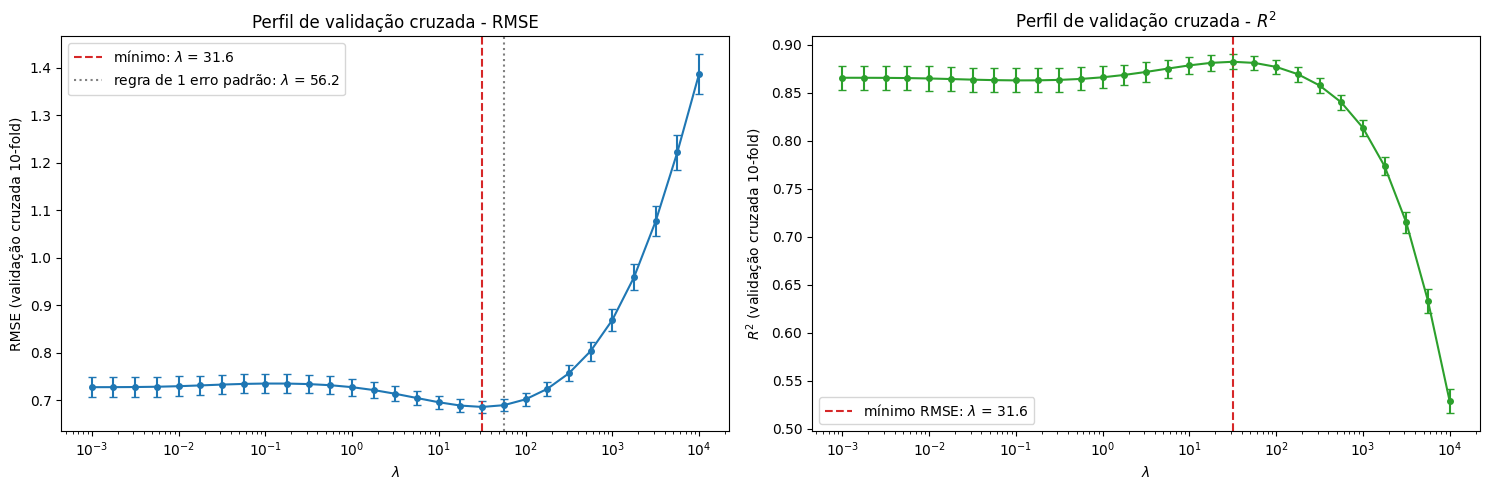

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].errorbar(grade_lambda, perfil_cv_ridge['RMSE_medio'], yerr=perfil_cv_ridge['RMSE_erro_padrao'],
                 marker='o', ms=4, capsize=3)
axes[0].axvline(lambda_otimo, color='tab:red', ls='--', label='mínimo: $\\lambda$ = %.1f' % lambda_otimo)
axes[0].axvline(lambda_1ep, color='tab:gray', ls=':', label='regra de 1 erro padrão: $\\lambda$ = %.1f' % lambda_1ep)
axes[0].set_xscale('log')
axes[0].set_xlabel('$\\lambda$')
axes[0].set_ylabel('RMSE (validação cruzada 10-fold)')
axes[0].set_title('Perfil de validação cruzada - RMSE')
axes[0].legend()

axes[1].errorbar(grade_lambda, perfil_cv_ridge['R2_medio'], yerr=perfil_cv_ridge['R2_erro_padrao'],
                 marker='o', ms=4, capsize=3, color='tab:green')
axes[1].axvline(lambda_otimo, color='tab:red', ls='--', label='mínimo RMSE: $\\lambda$ = %.1f' % lambda_otimo)
axes[1].set_xscale('log')
axes[1].set_xlabel('$\\lambda$')
axes[1].set_ylabel('$R^2$ (validação cruzada 10-fold)')
axes[1].set_title('Perfil de validação cruzada - $R^2$')
axes[1].legend()

plt.tight_layout()
salvar_figura('ridge_perfil_cv')
plt.show()


**Leitura do perfil de CV.** Com $\lambda$ muito pequeno, o RMSE de CV é praticamente o do OLS (0,7278 contra 0,7279). Ele sobe levemente
até cerca de 0,735 em $\lambda \approx 0{,}1$, cai até o mínimo de **0,6862 $\pm$ 0,0131 em $\lambda \approx 31{,}6$** ($R^2$ de CV
$0{,}8822 \pm 0{,}0077$) e depois cresce rapidamente, chegando a 1,3865 ($R^2$ 0,5286) em $\lambda = 10^4$, quando o modelo fica excessivamente
penalizado. O mínimo está no interior da grade, então o intervalo de busca foi suficiente. O $R^2$ é o espelho do RMSE.

A regra de um erro padrão escolheria $\lambda \approx 56{,}2$ (RMSE 0,6899). Como o enunciado pede o ótimo pelo RMSE, seguimos com o mínimo, e esse
modelo mais penalizado fica como alternativa.

**Comparação com `GridSearchCV`.** As duas buscas escolhem o mesmo $\lambda$ e têm o mesmo RMSE ótimo (0,6862). A diferença máxima nos perfis é de
$3{,}4 \times 10^{-4}$ no RMSE e $2{,}3 \times 10^{-4}$ no $R^2$, maior que no OLS, e tem causa identificada: o `StandardScaler` divide pelo desvio
com $n$, e `ajustar_preprocessamento` usa $n-1$. No OLS, reescalar as colunas não muda as previsões; no ridge, equivale a alterar levemente
$\lambda$. Repetindo a CV própria com a convenção do `StandardScaler`, a diferença máxima no perfil de RMSE cai para $1{,}1 \times 10^{-13}$.


## Modelo final e avaliação no conjunto de teste

Com $\lambda$ escolhido, o ridge é ajustado no **treino inteiro**, com o pré-processamento estimado no treino e
reaplicado ao teste. Para comparação, calculamos também o modelo equivalente do `sklearn`, o modelo da regra de um
erro padrão e o intervalo de 95% do desempenho de teste por bootstrap (5000 reamostras).


In [26]:
j_otimo = int(np.argmin(np.abs(grade_lambda - lambda_otimo)))
j_1ep = int(np.argmin(np.abs(grade_lambda - lambda_1ep)))
beta_ridge = coeficientes_ridge[:, j_otimo]

y_previsto_treino_ridge = X_treino_pad @ beta_ridge + media_y_ridge
y_previsto_teste_ridge = X_teste_pad @ beta_ridge + media_y_ridge
y_previsto_1ep_ridge = X_teste_pad @ coeficientes_ridge[:, j_1ep] + media_y_ridge

resultados_ridge = pd.DataFrame({
    'RMSE': [rmse(y_tr, y_previsto_treino_ridge), perfil_cv_ridge.loc[lambda_otimo, 'RMSE_medio'], rmse(y_teste.values, y_previsto_teste_ridge)],
    'R2': [r2(y_tr, y_previsto_treino_ridge), perfil_cv_ridge.loc[lambda_otimo, 'R2_medio'], r2(y_teste.values, y_previsto_teste_ridge)],
}, index=['treino (ajuste)', 'validação cruzada 10-fold', 'teste']).round(4)

print('Ridge com lambda = %.4f' % lambda_otimo)
print(resultados_ridge.to_string())

modelo_ridge_final = Ridge(alpha=lambda_otimo).fit(X_treino_pad, y_tr)
y_previsto_teste_ridge_sklearn = modelo_ridge_final.predict(X_teste_pad)
print('\nsklearn Ridge no teste: RMSE = %.4f, R2 = %.4f (diferenca maxima nas previsoes: %.2e)'
      % (rmse(y_teste.values, y_previsto_teste_ridge_sklearn), r2(y_teste.values, y_previsto_teste_ridge_sklearn),
         np.abs(y_previsto_teste_ridge - y_previsto_teste_ridge_sklearn).max()))
print('Ridge com lambda = %.1f (regra de 1 erro padrao): teste RMSE = %.4f, R2 = %.4f'
      % (lambda_1ep, rmse(y_teste.values, y_previsto_1ep_ridge), r2(y_teste.values, y_previsto_1ep_ridge)))
print('OLS no teste: RMSE = %.4f, R2 = %.4f'
      % (rmse(y_teste.values, y_previsto_teste_ols), r2(y_teste.values, y_previsto_teste_ols)))

gerador_ridge = np.random.default_rng(123)
y_te_ridge = y_teste.values
reamostras_ridge = np.empty((5000, 2))
for b in range(len(reamostras_ridge)):
    amostra = gerador_ridge.integers(0, len(y_te_ridge), len(y_te_ridge))
    reamostras_ridge[b] = rmse(y_te_ridge[amostra], y_previsto_teste_ridge[amostra]), r2(y_te_ridge[amostra], y_previsto_teste_ridge[amostra])
ic_teste_ridge = np.percentile(reamostras_ridge, [2.5, 97.5], axis=0)
print('\nIC 95%% (bootstrap) no teste: RMSE [%.4f, %.4f]   R2 [%.4f, %.4f]'
      % (ic_teste_ridge[0, 0], ic_teste_ridge[1, 0], ic_teste_ridge[0, 1], ic_teste_ridge[1, 1]))
print('Norma de beta: OLS = %.2f, ridge = %.2f' % (np.linalg.norm(beta_ols), np.linalg.norm(beta_ridge)))
print('Ridge: NumSulfer = %.3f, FP134 = %.3f' % (beta_ridge[posicao_sulfer], beta_ridge[posicao_fp134]))


Ridge com lambda = 31.6228
                             RMSE      R2
treino (ajuste)            0.5438  0.9293
validação cruzada 10-fold  0.6862  0.8822
teste                      0.7175  0.8805



sklearn Ridge no teste: RMSE = 0.7175, R2 = 0.8805 (diferenca maxima nas previsoes: 4.62e-14)
Ridge com lambda = 56.2 (regra de 1 erro padrao): teste RMSE = 0.7178, R2 = 0.8804
OLS no teste: RMSE = 0.7430, R2 = 0.8718

IC 95% (bootstrap) no teste: RMSE [0.6457, 0.7898]   R2 [0.8466, 0.9074]
Norma de beta: OLS = 152.02, ridge = 1.48
Ridge: NumSulfer = -0.057, FP134 = -0.056


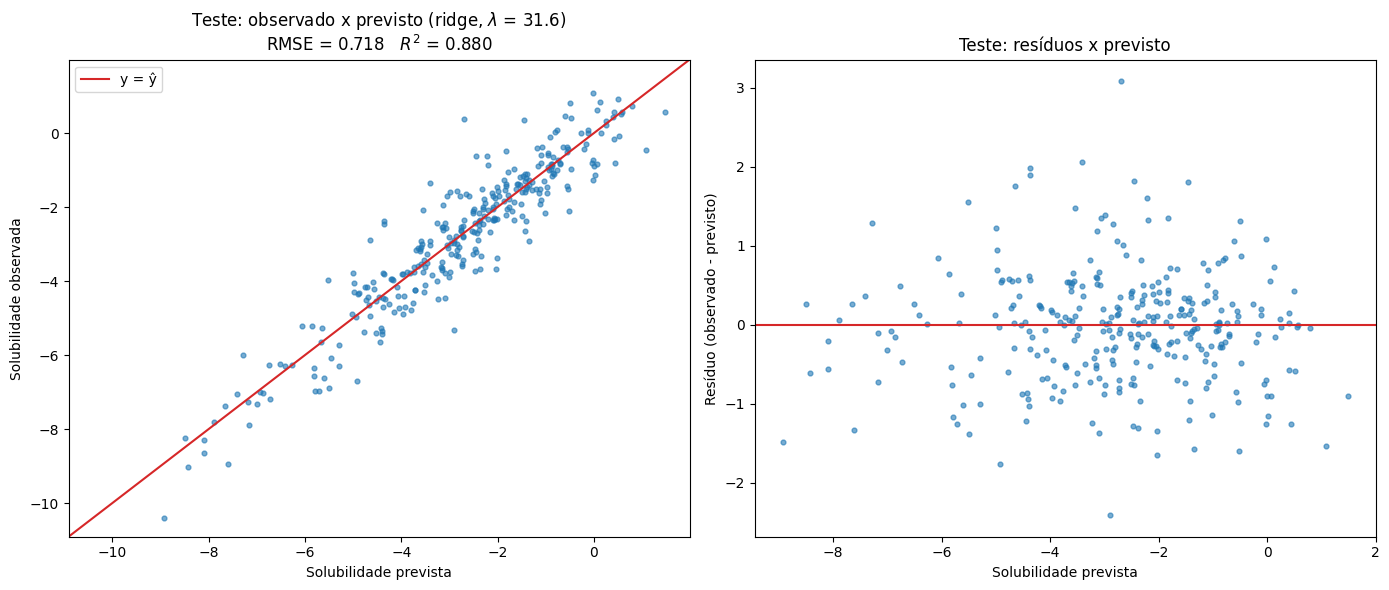

In [27]:
residuos_teste_ridge = y_teste.values - y_previsto_teste_ridge
limites_ridge = [min(y_teste.min(), y_previsto_teste_ridge.min()) - 0.5, max(y_teste.max(), y_previsto_teste_ridge.max()) + 0.5]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(y_previsto_teste_ridge, y_teste, s=12, alpha=0.6)
axes[0].plot(limites_ridge, limites_ridge, color='tab:red', lw=1.5, label='y = ŷ')
axes[0].set_xlim(limites_ridge)
axes[0].set_ylim(limites_ridge)
axes[0].set_xlabel('Solubilidade prevista')
axes[0].set_ylabel('Solubilidade observada')
axes[0].set_title('Teste: observado x previsto (ridge, $\\lambda$ = %.1f)\nRMSE = %.3f   $R^2$ = %.3f'
                  % (lambda_otimo, rmse(y_teste.values, y_previsto_teste_ridge), r2(y_teste.values, y_previsto_teste_ridge)))
axes[0].legend()

axes[1].scatter(y_previsto_teste_ridge, residuos_teste_ridge, s=12, alpha=0.6)
axes[1].axhline(0, color='tab:red', lw=1.5)
axes[1].set_xlabel('Solubilidade prevista')
axes[1].set_ylabel('Resíduo (observado - previsto)')
axes[1].set_title('Teste: resíduos x previsto')

plt.tight_layout()
salvar_figura('ridge_teste')
plt.show()


Assim como no PLS, e **só depois** de $\lambda$ estar escolhido, calculamos o erro de teste em toda a grade. Isso
não pode ser usado para escolher $\lambda$, mas mostra se o perfil de CV acompanhou o comportamento fora da amostra.


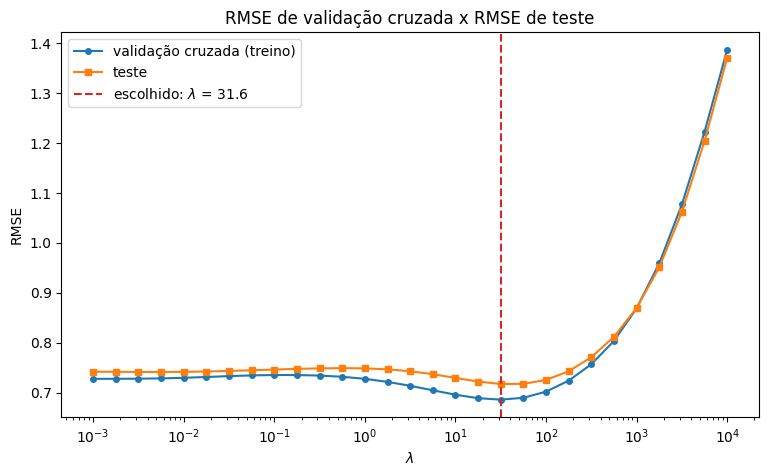

Menor RMSE de teste: 0.7175 com lambda = 31.62 (apenas informativo)


In [28]:
previsoes_teste_ridge = X_teste_pad @ coeficientes_ridge + media_y_ridge
rmse_teste_ridge = [rmse(y_teste.values, previsoes_teste_ridge[:, j]) for j in range(len(grade_lambda))]

plt.figure(figsize=(9, 5))
plt.plot(grade_lambda, perfil_cv_ridge['RMSE_medio'], marker='o', ms=4, label='validação cruzada (treino)')
plt.plot(grade_lambda, rmse_teste_ridge, marker='s', ms=4, label='teste')
plt.axvline(lambda_otimo, color='tab:red', ls='--', label='escolhido: $\\lambda$ = %.1f' % lambda_otimo)
plt.xscale('log')
plt.xlabel('$\\lambda$')
plt.ylabel('RMSE')
plt.title('RMSE de validação cruzada x RMSE de teste')
plt.legend()
salvar_figura('ridge_cv_vs_teste')
plt.show()

print('Menor RMSE de teste: %.4f com lambda = %.2f (apenas informativo)'
      % (min(rmse_teste_ridge), grade_lambda[int(np.argmin(rmse_teste_ridge))]))


**Resultados no conjunto de teste.** O ridge com $\lambda \approx 31{,}6$, ajustado só no treino, obteve no teste
**RMSE ≈ 0,7175 e $R^2$ ≈ 0,8805**, com IC de 95% por bootstrap de $[0{,}646;\ 0{,}790]$ para o RMSE e $[0{,}847;\ 0{,}907]$
para o $R^2$. O `sklearn` produz o mesmo resultado (diferença máxima de $4{,}6 \times 10^{-14}$ nas previsões). No treino, o
RMSE é 0,5438 e o $R^2$ é 0,9293.

Frente ao OLS (RMSE 0,7430, $R^2$ 0,8718), a penalização reduziu o RMSE de teste em 0,0255 e encolheu a norma dos coeficientes
de 152,02 para 1,48. No par colinear, `NumSulfer` e `FP134` passam a valer $-0{,}057$ e $-0{,}056$, em vez de $\mp 106$. A diferença
entre os modelos no teste é pequena diante da largura dos intervalos, e a comparação estatística formal é feita mais adiante.

A estimativa de CV ficou mais otimista que a do OLS: o RMSE de CV (0,6862) está 0,0313 abaixo do RMSE de teste, cerca de 2,4 erros
padrão da CV. Parte disso é esperada, pois $\lambda$ foi escolhido justamente por minimizar esse valor (viés de seleção). O RMSE de CV
ainda está dentro do intervalo de bootstrap do teste, e o $R^2$ de CV (0,8822) é próximo do de teste (0,8805).

A curva de RMSE de teste acompanha a de CV em toda a grade, e seu mínimo na grade também ocorre em $\lambda \approx 31{,}6$. O modelo da regra de
um erro padrão ($\lambda \approx 56{,}2$) tem desempenho praticamente igual no teste (RMSE 0,7178, $R^2$ 0,8804), então, nessa região, a escolha
exata de $\lambda$ pouco importa. Os resíduos se distribuem em torno de zero, sem tendência clara com o valor previsto; o maior deles é de cerca de 3 unidades de log.


# 3. REGRESSÃO PLS (PARTIAL LEAST SQUARES)

Entre PLS e PCR escolhemos o **PLS**. A análise do item 0 mostrou que há forte multicolinearidade
entre os preditores, e os dois métodos lidam com isso projetando os dados em poucas componentes
latentes. A diferença está em como essas componentes são escolhidas. O PCR escolhe as direções de
maior variância de $X$ sem olhar a saída, então nada garante que as primeiras componentes sejam as
que explicam a solubilidade. O PLS escolhe as direções de maior **covariância** entre $X$ e $y$. Com
isso ele costuma precisar de menos componentes para chegar ao mesmo erro, e é a escolha natural aqui.

Assim como no PCA do HW1, implementamos tudo na mão com numpy, sem sklearn: o algoritmo PLS, a
validação cruzada e as métricas.

Os preditores do modelo são os preparados na seção anterior (Yeo-Johnson nos 20 não binários,
binários intactos, centralização e escalonamento). O escalonamento é necessário porque o PLS busca
direções de máxima covariância, e sem ele os preditores de escala maior (como `MolWeight`) dominariam
as componentes só por causa da unidade.


## Algoritmo PLS (NIPALS)

Com uma única saída, o PLS (algoritmo NIPALS) é bem curto. Partindo de $X$ padronizado e de $y$
centrado, a cada componente $a$:

1. o vetor de pesos é a direção de maior covariância com a saída: $w_a = X^T y / \|X^T y\|$;
2. os *scores* são a projeção dos dados nessa direção: $t_a = X w_a$;
3. os *loadings* de $X$ e o coeficiente de $y$ vêm de regressões em $t_a$: $p_a = X^T t_a / (t_a^T t_a)$ e $q_a = y^T t_a / (t_a^T t_a)$;
4. a parte explicada é removida (deflação): $X \leftarrow X - t_a p_a^T$ e $y \leftarrow y - q_a t_a$.

Com $A$ componentes, os coeficientes de regressão nos preditores originais (padronizados) são

$$ \beta_A = W_A (P_A^T W_A)^{-1} q_A $$

e a predição é $\hat y = \bar y + X_{\text{pad}}\, \beta_A$. A função abaixo devolve de uma vez os
coeficientes para $A = 1, 2, \dots, A_{\max}$, o que deixa a validação cruzada barata: um único ajuste
por fold dá as predições de todos os números de componentes.

In [29]:
def pls_nipals(X, y, n_componentes):
    """PLS1 por NIPALS. X ja padronizado. Devolve a matriz de coeficientes (p x A), uma coluna por
    numero de componentes, e a media de y."""
    X = X.copy()
    media_y = y.mean()
    y = y - media_y
    n, p = X.shape
    W = np.zeros((p, n_componentes))
    P = np.zeros((p, n_componentes))
    q = np.zeros(n_componentes)

    for a in range(n_componentes):
        w = X.T @ y
        w = w / np.linalg.norm(w)        # direcao de maxima covariancia com y
        t = X @ w                        # scores
        tt = t @ t
        P[:, a] = X.T @ t / tt           # loadings de X
        q[a] = y @ t / tt                # coeficiente de y em t
        W[:, a] = w
        X = X - np.outer(t, P[:, a])     # deflacao
        y = y - q[a] * t

    coeficientes = np.zeros((p, n_componentes))
    for a in range(1, n_componentes + 1):
        coeficientes[:, a - 1] = W[:, :a] @ np.linalg.solve(P[:, :a].T @ W[:, :a], q[:a])
    return coeficientes, media_y

Uma verificação rápida da implementação: com o número máximo de componentes (igual ao posto de $X$),
o PLS tem que reproduzir exatamente a regressão linear por mínimos quadrados. Testamos isso num
problema pequeno e aleatório.

In [30]:
gerador = np.random.default_rng(0)
X_teste_pls = gerador.normal(size=(60, 8))
X_teste_pls = (X_teste_pls - X_teste_pls.mean(0)) / X_teste_pls.std(0, ddof=1)
y_teste_pls = X_teste_pls @ gerador.normal(size=8) + gerador.normal(size=60)

beta_pls, _ = pls_nipals(X_teste_pls, y_teste_pls, 8)
beta_mq = np.linalg.lstsq(X_teste_pls, y_teste_pls - y_teste_pls.mean(), rcond=None)[0]
print('Diferenca maxima PLS (8 comp.) x minimos quadrados:', np.abs(beta_pls[:, -1] - beta_mq).max())

Diferenca maxima PLS (8 comp.) x minimos quadrados: 2.220446049250313e-15


## Escolha do número de componentes por validação cruzada (10-fold)

Usamos **validação cruzada 10-fold só no conjunto de treino**. As 951 observações são embaralhadas
(semente fixa, para o resultado ser reproduzível) e divididas em 10 folds de cerca de 95 compostos.
Para cada fold $k$:

1. o pré-processamento é estimado nos outros 9 folds;
2. o PLS é ajustado nesses 9 folds com até $A_{\max} = 40$ componentes;
3. o fold $k$ é pré-processado com os parâmetros do passo 1 e previsto com cada número de componentes;
4. guardamos o RMSE e o $R^2 = 1 - \text{SSE}/\text{SST}$ do fold $k$ para cada $A$.

O perfil de CV é a média dos 10 folds para cada $A$, com o erro padrão $\text{dp}/\sqrt{10}$ como
barra de incerteza. O número ótimo de componentes é o que **minimiza o RMSE médio de CV**.

In [31]:
A_MAX = 40

rmse_cv = np.zeros((N_FOLDS, A_MAX))
r2_cv = np.zeros((N_FOLDS, A_MAX))

for k, indices_validacao in enumerate(folds):
    indices_ajuste = np.setdiff1d(np.arange(len(y_tr)), indices_validacao)

    parametros = ajustar_preprocessamento(X_treino.iloc[indices_ajuste])  # so com os 9 folds
    X_ajuste = aplicar_preprocessamento(X_treino.iloc[indices_ajuste], parametros)
    X_validacao = aplicar_preprocessamento(X_treino.iloc[indices_validacao], parametros)

    coeficientes, media_y = pls_nipals(X_ajuste, y_tr[indices_ajuste], A_MAX)
    previsoes = X_validacao @ coeficientes + media_y  # uma coluna por numero de componentes

    for a in range(A_MAX):
        rmse_cv[k, a] = rmse(y_tr[indices_validacao], previsoes[:, a])
        r2_cv[k, a] = r2(y_tr[indices_validacao], previsoes[:, a])

perfil_cv = pd.DataFrame({
    'RMSE_medio': rmse_cv.mean(0),
    'RMSE_erro_padrao': rmse_cv.std(0, ddof=1) / np.sqrt(N_FOLDS),
    'R2_medio': r2_cv.mean(0),
    'R2_erro_padrao': r2_cv.std(0, ddof=1) / np.sqrt(N_FOLDS),
}, index=pd.Index(range(1, A_MAX + 1), name='componentes'))

A_otimo = int(perfil_cv['RMSE_medio'].idxmin())
limite_1ep = perfil_cv.loc[A_otimo, 'RMSE_medio'] + perfil_cv.loc[A_otimo, 'RMSE_erro_padrao']
A_1ep = int(perfil_cv.index[perfil_cv['RMSE_medio'] <= limite_1ep][0])

print(perfil_cv.round(4).to_string())
print('\nNumero otimo de componentes (minimo RMSE de CV):', A_otimo)
print('  RMSE CV = %.4f +- %.4f   R2 CV = %.4f'
      % (perfil_cv.loc[A_otimo, 'RMSE_medio'], perfil_cv.loc[A_otimo, 'RMSE_erro_padrao'], perfil_cv.loc[A_otimo, 'R2_medio']))
print('Menor modelo dentro de 1 erro padrao do minimo:', A_1ep)

             RMSE_medio  RMSE_erro_padrao  R2_medio  R2_erro_padrao
componentes                                                        
1                1.2895            0.0355    0.5856          0.0274
2                1.0628            0.0255    0.7200          0.0138
3                0.9464            0.0252    0.7788          0.0091
4                0.8733            0.0172    0.8091          0.0123
5                0.8240            0.0232    0.8307          0.0106
6                0.7881            0.0217    0.8448          0.0105
7                0.7589            0.0169    0.8559          0.0096
8                0.7477            0.0141    0.8594          0.0101
9                0.7359            0.0145    0.8631          0.0110
10               0.7255            0.0137    0.8674          0.0101
11               0.7212            0.0145    0.8685          0.0109
12               0.7147            0.0135    0.8715          0.0096
13               0.7159            0.0135    0.8

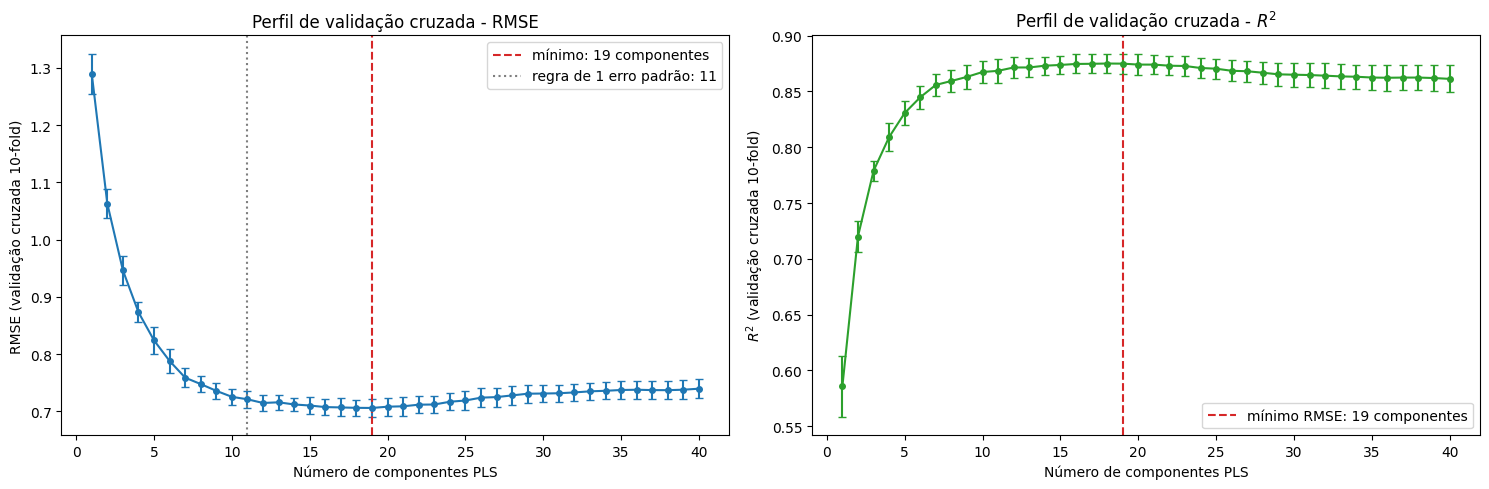

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
componentes = perfil_cv.index

axes[0].errorbar(componentes, perfil_cv['RMSE_medio'], yerr=perfil_cv['RMSE_erro_padrao'],
                 marker='o', ms=4, capsize=3)
axes[0].axvline(A_otimo, color='tab:red', ls='--', label='mínimo: %d componentes' % A_otimo)
axes[0].axvline(A_1ep, color='tab:gray', ls=':', label='regra de 1 erro padrão: %d' % A_1ep)
axes[0].set_xlabel('Número de componentes PLS')
axes[0].set_ylabel('RMSE (validação cruzada 10-fold)')
axes[0].set_title('Perfil de validação cruzada - RMSE')
axes[0].legend()

axes[1].errorbar(componentes, perfil_cv['R2_medio'], yerr=perfil_cv['R2_erro_padrao'],
                 marker='o', ms=4, capsize=3, color='tab:green')
axes[1].axvline(A_otimo, color='tab:red', ls='--', label='mínimo RMSE: %d componentes' % A_otimo)
axes[1].set_xlabel('Número de componentes PLS')
axes[1].set_ylabel('$R^2$ (validação cruzada 10-fold)')
axes[1].set_title('Perfil de validação cruzada - $R^2$')
axes[1].legend()

plt.tight_layout()
salvar_figura('pls_perfil_cv')
plt.show()

**Leitura do perfil de CV.** O RMSE cai rápido nas primeiras componentes: vai de cerca de 1,29 com
uma componente para 0,79 com seis e 0,73 com dez. Depois disso o ganho é pequeno, e o mínimo fica em
**19 componentes** (RMSE de CV ≈ 0,706, $R^2$ ≈ 0,875). A partir daí o erro volta a subir devagar,
porque as componentes extras passam a ajustar ruído do treino (sobreajuste). O $R^2$ é o espelho do
RMSE: sobe até cerca de 0,875 e depois cai um pouco.

A curva é bem achatada entre 12 e 22 componentes, com diferenças menores que o erro padrão. A regra de
um erro padrão escolheria um modelo mais enxuto, com 11 componentes, sem perda estatisticamente
relevante. Como o enunciado pede o ótimo pelo RMSE, seguimos com o mínimo (19 componentes), e o
modelo de 11 fica registrado como alternativa mais parcimoniosa.

## Modelo final e avaliação no conjunto de teste

Com o número de componentes escolhido, reestimamos o pré-processamento e o PLS no **treino inteiro**
(951 compostos). Depois aplicamos ao teste exatamente a mesma transformação, com os $\lambda$, médias e
desvios do treino, e calculamos RMSE e $R^2$. É a primeira e única vez que o teste é usado.

In [33]:
coeficientes_finais, media_y_final = pls_nipals(X_treino_pad, y_tr, A_MAX)
beta_final = coeficientes_finais[:, A_otimo - 1]

y_previsto_treino = X_treino_pad @ beta_final + media_y_final
y_previsto_teste = X_teste_pad @ beta_final + media_y_final

resultados = pd.DataFrame({
    'RMSE': [rmse(y_tr, y_previsto_treino), perfil_cv.loc[A_otimo, 'RMSE_medio'], rmse(y_teste.values, y_previsto_teste)],
    'R2': [r2(y_tr, y_previsto_treino), perfil_cv.loc[A_otimo, 'R2_medio'], r2(y_teste.values, y_previsto_teste)],
}, index=['treino (ajuste)', 'validação cruzada 10-fold', 'teste']).round(4)

print('PLS com %d componentes' % A_otimo)
print(resultados.to_string())

y_previsto_1ep = X_teste_pad @ coeficientes_finais[:, A_1ep - 1] + media_y_final
print('\nPara comparacao, PLS com %d componentes (regra de 1 erro padrao): teste RMSE = %.4f, R2 = %.4f'
      % (A_1ep, rmse(y_teste.values, y_previsto_1ep), r2(y_teste.values, y_previsto_1ep)))

PLS com 19 componentes
                             RMSE      R2
treino (ajuste)            0.5384  0.9307
validação cruzada 10-fold  0.7060  0.8750
teste                      0.7337  0.8750

Para comparacao, PLS com 11 componentes (regra de 1 erro padrao): teste RMSE = 0.7179, R2 = 0.8803


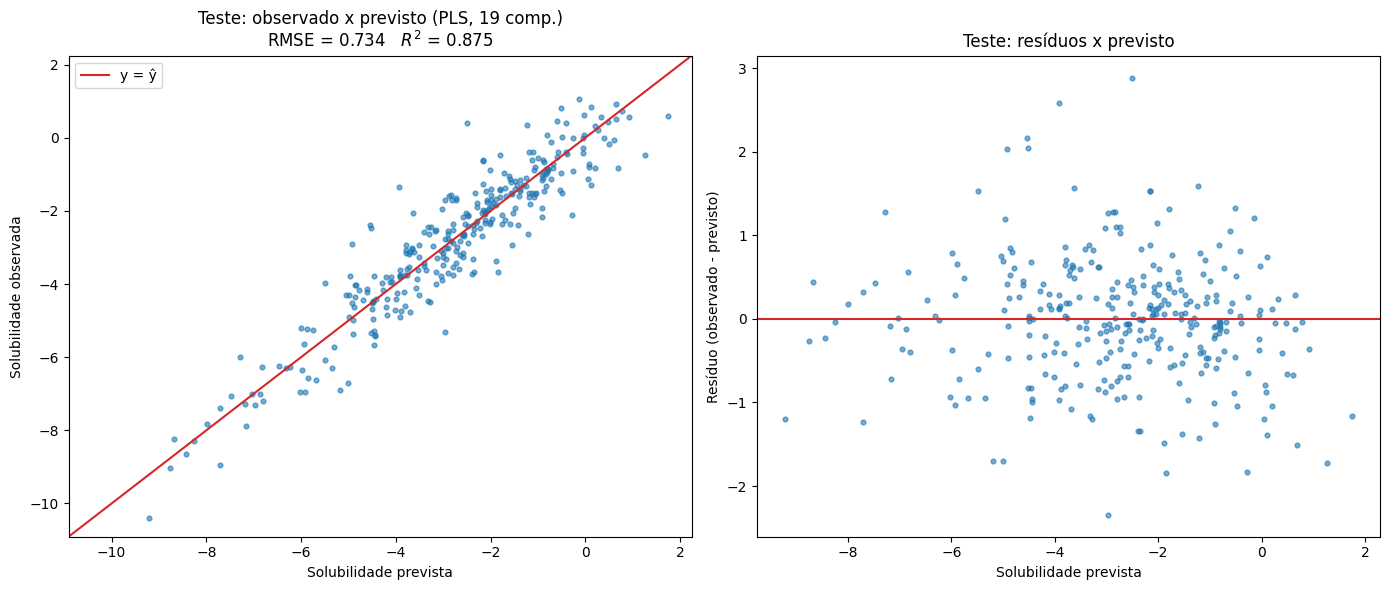

In [34]:
residuos_teste = y_teste.values - y_previsto_teste
limites = [min(y_teste.min(), y_previsto_teste.min()) - 0.5, max(y_teste.max(), y_previsto_teste.max()) + 0.5]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].scatter(y_previsto_teste, y_teste, s=12, alpha=0.6)
axes[0].plot(limites, limites, color='tab:red', lw=1.5, label='y = ŷ')
axes[0].set_xlim(limites)
axes[0].set_ylim(limites)
axes[0].set_xlabel('Solubilidade prevista')
axes[0].set_ylabel('Solubilidade observada')
axes[0].set_title('Teste: observado x previsto (PLS, %d comp.)\nRMSE = %.3f   $R^2$ = %.3f'
                  % (A_otimo, rmse(y_teste.values, y_previsto_teste), r2(y_teste.values, y_previsto_teste)))
axes[0].legend()

axes[1].scatter(y_previsto_teste, residuos_teste, s=12, alpha=0.6)
axes[1].axhline(0, color='tab:red', lw=1.5)
axes[1].set_xlabel('Solubilidade prevista')
axes[1].set_ylabel('Resíduo (observado - previsto)')
axes[1].set_title('Teste: resíduos x previsto')

plt.tight_layout()
salvar_figura('pls_teste')
plt.show()

Por curiosidade, e **só depois** de o modelo já estar escolhido, calculamos o erro de teste para todos
os números de componentes. Isso não pode ser usado para escolher $A$ (seria usar o teste no ajuste),
mas mostra se a curva de CV foi uma boa estimativa do comportamento fora da amostra.

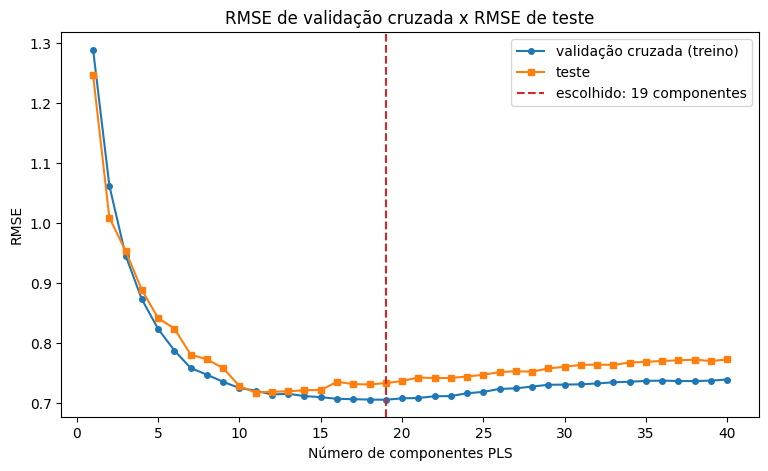

Menor RMSE de teste: 0.7179 com 11 componentes (apenas informativo)


In [35]:
previsoes_teste_todos = X_teste_pad @ coeficientes_finais + media_y_final
rmse_teste_todos = [rmse(y_teste.values, previsoes_teste_todos[:, a]) for a in range(A_MAX)]

plt.figure(figsize=(9, 5))
plt.plot(componentes, perfil_cv['RMSE_medio'], marker='o', ms=4, label='validação cruzada (treino)')
plt.plot(componentes, rmse_teste_todos, marker='s', ms=4, label='teste')
plt.axvline(A_otimo, color='tab:red', ls='--', label='escolhido: %d componentes' % A_otimo)
plt.xlabel('Número de componentes PLS')
plt.ylabel('RMSE')
plt.title('RMSE de validação cruzada x RMSE de teste')
plt.legend()
salvar_figura('pls_cv_vs_teste')
plt.show()

print('Menor RMSE de teste: %.4f com %d componentes (apenas informativo)'
      % (min(rmse_teste_todos), int(np.argmin(rmse_teste_todos)) + 1))

**Resultados no conjunto de teste.** O PLS com 19 componentes, ajustado só no treino, obteve no teste
**RMSE ≈ 0,73 e $R^2$ ≈ 0,87**. Isso é praticamente igual à estimativa de CV (RMSE ≈ 0,71,
$R^2$ ≈ 0,875). O erro de treino é menor (RMSE ≈ 0,54, $R^2$ ≈ 0,93), o que é esperado porque o
modelo foi ajustado nesses dados. O que importa é que a CV, calculada só no treino, previu bem o erro
de teste: a escolha de componentes não ficou otimista. Para ter uma referência, a
solubilidade de teste tem desvio padrão perto de 2, então o modelo reduz o erro de uma predição pela
média em cerca de dois terços.

A curva de RMSE de teste acompanha a de CV, com o mesmo formato: queda forte até cerca de 10
componentes e um platô depois. Isso confirma que a validação cruzada foi um bom critério de escolha.
O modelo mais enxuto de 11 componentes (regra de um erro padrão) chega a ser levemente melhor no teste
(RMSE ≈ 0,72, $R^2$ ≈ 0,88). A diferença está dentro da incerteza da CV, mas reforça que, no platô,
componentes a mais não trazem ganho real.

No gráfico observado x previsto os pontos seguem a diagonal em toda a faixa de solubilidade, inclusive
nos poucos compostos muito insolúveis. Os resíduos ficam espalhados em torno de zero, sem tendência
clara nem aumento de variância com o valor previsto; a maioria está entre -1,5 e 1,5. Os poucos erros
grandes (até cerca de 3 unidades de log) estão na faixa central, entre -5 e -2, e correspondem a
compostos específicos mal previstos, não a um viés sistemático. Ainda assim, o item 0 mostrou que
algumas relações preditor-saída têm curvatura, e um modelo linear como o PLS não captura isso. Fica
espaço para modelos não lineares reduzirem o erro restante.

# 4. REDE NEURAL PARA REGRESSÃO

Agora trocamos o modelo linear por um não linear: uma rede neural *feedforward* (perceptron
multicamadas, MLP) implementada em **PyTorch**. A rede recebe os 228 preditores transformados e devolve
a solubilidade prevista. Cada camada oculta faz uma combinação linear dos preditores seguida de uma
ativação não linear (ReLU, $\max(0, z)$), e a camada de saída é linear, como convém a um problema de
regressão:

$$ \hat y = W_{\text{saída}}\, \text{ReLU}\big(W_L \cdots \text{ReLU}(W_1 x + b_1) \cdots + b_L\big) + b_{\text{saída}} $$

## Pré-processamento

É exatamente o mesmo do PLS, com as mesmas funções `ajustar_preprocessamento` e
`aplicar_preprocessamento` da preparação comum: Yeo-Johnson nos 20 preditores não binários, seguida de
centralização e escalonamento. Os parâmetros são estimados só nos dados de ajuste e reaplicados nos
dados avaliados, tanto dentro da validação cruzada quanto no teste final. Para redes neurais a
padronização é ainda mais importante que no PLS: com entradas em escalas muito diferentes, o gradiente
fica desbalanceado e o treinamento converge mal.

Também padronizamos a **saída** (média 0, desvio 1, com a média e o desvio do conjunto de ajuste). As
predições são convertidas de volta para a escala original antes de calcular RMSE e $R^2$.

## Treinamento

- função de custo: erro quadrático médio (MSE);
- otimizador: AdamW (Adam com *weight decay* desacoplado), taxa de aprendizado $10^{-3}$, mini-lotes de 64 compostos;
- regularização: *weight decay* (penalidade L2 nos pesos) e *dropout* nas camadas ocultas.

Com só 951 compostos para 228 preditores, uma rede pode facilmente decorar o treino. Por isso os
hiperparâmetros que controlam a complexidade e a regularização são escolhidos por validação cruzada.

In [36]:
import time
import itertools
import torch
import torch.nn as nn

torch.set_num_threads(1)  # a rede e pequena: com 1 thread o treino fica mais rapido (menos overhead)
print('PyTorch', torch.__version__)

def criar_rede(n_entradas, camadas_ocultas, dropout):
    camadas = []
    entrada = n_entradas
    for neuronios in camadas_ocultas:
        camadas += [nn.Linear(entrada, neuronios), nn.ReLU(), nn.Dropout(dropout)]
        entrada = neuronios
    camadas.append(nn.Linear(entrada, 1))  # saida linear (regressao)
    return nn.Sequential(*camadas)

def treinar_rede(X_ajuste, y_ajuste, camadas_ocultas, weight_decay, dropout, epocas,
                 X_avaliacao=None, y_avaliacao=None, checkpoints=(), semente=0,
                 taxa_aprendizado=1e-3, tamanho_lote=64):
    """Treina a rede e devolve (rede, media_y, desvio_y, rmse_por_checkpoint).
    Se X_avaliacao for passado, calcula o RMSE nele nas epocas listadas em checkpoints."""
    torch.manual_seed(semente)
    gerador = torch.Generator().manual_seed(semente)

    media_y, desvio_y = y_ajuste.mean(), y_ajuste.std()
    X_t = torch.tensor(X_ajuste, dtype=torch.float32)
    y_t = torch.tensor((y_ajuste - media_y) / desvio_y, dtype=torch.float32).unsqueeze(1)

    rede = criar_rede(X_t.shape[1], camadas_ocultas, dropout)
    otimizador = torch.optim.AdamW(rede.parameters(), lr=taxa_aprendizado, weight_decay=weight_decay)
    rmse_checkpoints = {}

    for epoca in range(1, epocas + 1):
        rede.train()
        for lote in torch.randperm(len(X_t), generator=gerador).split(tamanho_lote):
            otimizador.zero_grad()
            custo = ((rede(X_t[lote]) - y_t[lote]) ** 2).mean()
            custo.backward()
            otimizador.step()
        if X_avaliacao is not None and epoca in checkpoints:
            previsto = prever_rede(rede, X_avaliacao, media_y, desvio_y)
            rmse_checkpoints[epoca] = rmse(y_avaliacao, previsto)

    return rede, media_y, desvio_y, rmse_checkpoints

def prever_rede(rede, X, media_y, desvio_y):
    rede.eval()  # desliga o dropout
    with torch.no_grad():
        saida = rede(torch.tensor(X, dtype=torch.float32)).numpy().ravel()
    return saida * desvio_y + media_y  # volta para a escala original da solubilidade

PyTorch 2.15.0+cpu


## Busca dos hiperparâmetros por validação cruzada (5-fold)

Os hiperparâmetros avaliados são:

| hiperparâmetro | valores |
|---|---|
| arquitetura (neurônios por camada oculta) | (16), (64), (128), (64, 32) |
| *weight decay* | 0,01; 0,1; 1 |
| *dropout* | 0; 0,3 |
| número de épocas | 25, 50, ..., 300 |

Isso dá 4 × 3 × 2 = 24 redes por fold. O número de épocas não precisa de treinos separados: em cada
treino medimos o RMSE no fold de validação a cada 25 épocas. Assim cada configuração já devolve um
perfil de erro ao longo do treinamento, e a parada no ponto certo (*early stopping*) vira um
hiperparâmetro escolhido pela CV, como o número de componentes no PLS.

Usamos **5 folds**, e não 10 como no PLS, porque cada ajuste de rede é bem mais caro que um ajuste do
PLS. Com 24 configurações, 5 folds já são 120 treinos de 300 épocas. Os folds são sorteados com
semente fixa, e só o conjunto de treino é usado. A melhor combinação é a de menor RMSE médio nos 5 folds.

In [37]:
N_FOLDS_RN = 5
EPOCAS_MAX = 300
CHECKPOINTS = list(range(25, EPOCAS_MAX + 1, 25))

grade = {
    'camadas_ocultas': [(16,), (64,), (128,), (64, 32)],
    'weight_decay': [0.01, 0.1, 1.0],
    'dropout': [0.0, 0.3],
}

gerador = np.random.default_rng(42)
folds_rn = np.array_split(gerador.permutation(len(y_tr)), N_FOLDS_RN)

# pre-processamento de cada fold calculado uma vez so (nao depende da configuracao da rede)
dados_folds = []
for indices_validacao in folds_rn:
    indices_ajuste = np.setdiff1d(np.arange(len(y_tr)), indices_validacao)
    parametros = ajustar_preprocessamento(X_treino.iloc[indices_ajuste])
    dados_folds.append((aplicar_preprocessamento(X_treino.iloc[indices_ajuste], parametros), y_tr[indices_ajuste],
                        aplicar_preprocessamento(X_treino.iloc[indices_validacao], parametros), y_tr[indices_validacao]))

linhas = []
inicio = time.time()
for camadas_ocultas, weight_decay, dropout in itertools.product(*grade.values()):
    rmse_folds = np.zeros((N_FOLDS_RN, len(CHECKPOINTS)))
    for k, (X_aj, y_aj, X_val, y_val) in enumerate(dados_folds):
        _, _, _, rmse_ck = treinar_rede(X_aj, y_aj, camadas_ocultas, weight_decay, dropout, EPOCAS_MAX,
                                        X_val, y_val, CHECKPOINTS)
        rmse_folds[k] = [rmse_ck[e] for e in CHECKPOINTS]
    for j, epocas in enumerate(CHECKPOINTS):
        linhas.append({'camadas_ocultas': str(camadas_ocultas), 'weight_decay': weight_decay, 'dropout': dropout,
                       'epocas': epocas, 'RMSE_medio': rmse_folds[:, j].mean(),
                       'RMSE_erro_padrao': rmse_folds[:, j].std(ddof=1) / np.sqrt(N_FOLDS_RN)})
    melhor_local = rmse_folds.mean(0).argmin()
    print('%-9s wd=%-5s dropout=%-4s  melhor: %3d epocas, RMSE CV = %.4f   (%.0f s)'
          % (camadas_ocultas, weight_decay, dropout, CHECKPOINTS[melhor_local],
             rmse_folds.mean(0)[melhor_local], time.time() - inicio))

resultados_cv_rn = pd.DataFrame(linhas)

(16,)     wd=0.01  dropout=0.0   melhor:  50 epocas, RMSE CV = 0.6809   (14 s)


(16,)     wd=0.01  dropout=0.3   melhor: 100 epocas, RMSE CV = 0.6767   (26 s)


(16,)     wd=0.1   dropout=0.0   melhor:  50 epocas, RMSE CV = 0.6761   (38 s)


(16,)     wd=0.1   dropout=0.3   melhor: 175 epocas, RMSE CV = 0.6752   (51 s)


(16,)     wd=1.0   dropout=0.0   melhor: 125 epocas, RMSE CV = 0.6470   (62 s)


(16,)     wd=1.0   dropout=0.3   melhor: 300 epocas, RMSE CV = 0.6656   (75 s)


... (14 outputs left out)

(64, 32)  wd=0.1   dropout=0.0   melhor: 300 epocas, RMSE CV = 0.6536   (306 s)


(64, 32)  wd=0.1   dropout=0.3   melhor: 125 epocas, RMSE CV = 0.6454   (325 s)


(64, 32)  wd=1.0   dropout=0.0   melhor: 100 epocas, RMSE CV = 0.6503   (341 s)


(64, 32)  wd=1.0   dropout=0.3   melhor: 225 epocas, RMSE CV = 0.6366   (359 s)


In [38]:
melhor = resultados_cv_rn.loc[resultados_cv_rn['RMSE_medio'].idxmin()]
melhor_camadas = eval(melhor['camadas_ocultas'])
melhor_wd = float(melhor['weight_decay'])
melhor_dropout = float(melhor['dropout'])
melhor_epocas = int(melhor['epocas'])

print('Melhor configuracao da rede (validacao cruzada 5-fold):')
print('  camadas ocultas:', melhor_camadas)
print('  weight decay:   ', melhor_wd)
print('  dropout:        ', melhor_dropout)
print('  epocas:         ', melhor_epocas)
print('  RMSE CV = %.4f +- %.4f' % (melhor['RMSE_medio'], melhor['RMSE_erro_padrao']))

# melhor RMSE (escolhendo as epocas) de cada combinacao, para comparar as configuracoes
resumo = (resultados_cv_rn.loc[resultados_cv_rn.groupby(['camadas_ocultas', 'weight_decay', 'dropout'])['RMSE_medio'].idxmin()]
          .sort_values('RMSE_medio').reset_index(drop=True))
print('\nTodas as configuracoes, cada uma no seu melhor numero de epocas:')
print(resumo.round(4).to_string())

Melhor configuracao da rede (validacao cruzada 5-fold):
  camadas ocultas: (64,)
  weight decay:    1.0
  dropout:         0.3
  epocas:          100
  RMSE CV = 0.6289 +- 0.0204

Todas as configuracoes, cada uma no seu melhor numero de epocas:
   camadas_ocultas  weight_decay  dropout  epocas  RMSE_medio  RMSE_erro_padrao
0            (64,)          1.00      0.3     100      0.6289            0.0204
1           (128,)          1.00      0.0      75      0.6291            0.0135
2           (128,)          0.10      0.3      50      0.6324            0.0115
3           (128,)          1.00      0.3      50      0.6328            0.0144
4           (128,)          0.01      0.3      50      0.6333            0.0129
5            (64,)          1.00      0.0     100      0.6336            0.0272
6         (64, 32)          1.00      0.3     225      0.6366            0.0131
7            (64,)          0.01      0.3     200      0.6367            0.0175
8            (64,)          0.10   

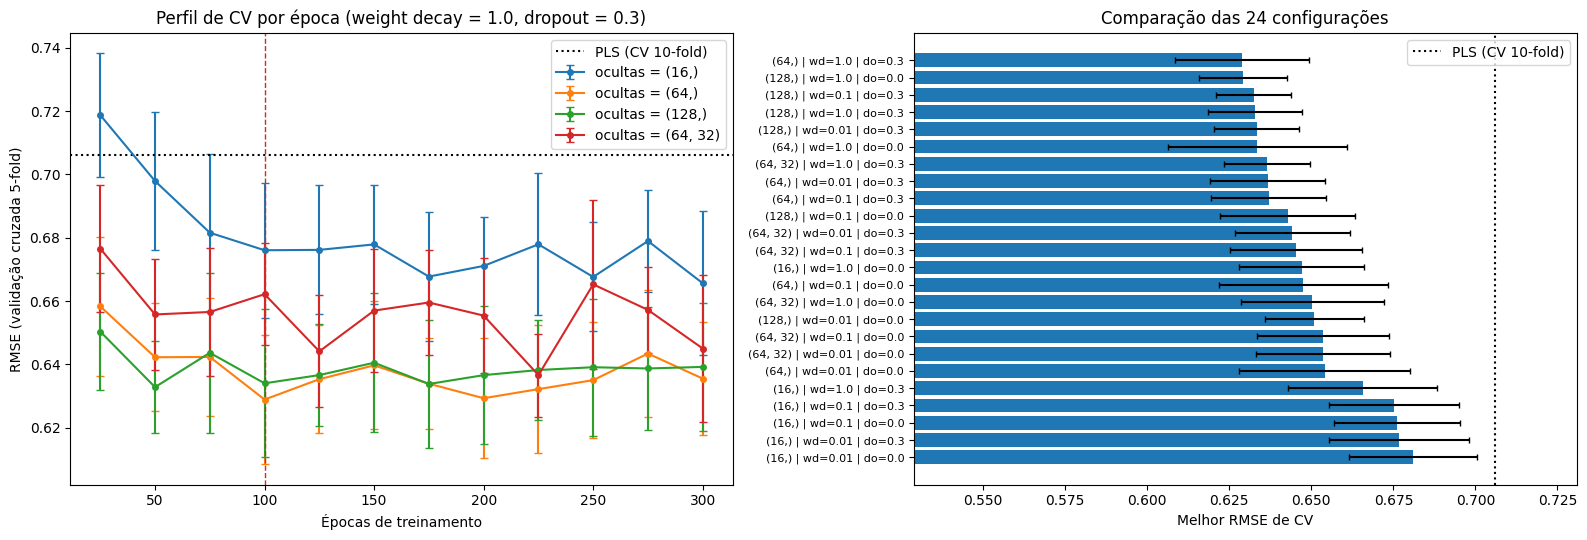

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# perfil ao longo das epocas: as 4 arquiteturas com o weight decay e o dropout escolhidos
for camadas in grade['camadas_ocultas']:
    curva = resultados_cv_rn[(resultados_cv_rn['camadas_ocultas'] == str(camadas))
                             & (resultados_cv_rn['weight_decay'] == melhor_wd)
                             & (resultados_cv_rn['dropout'] == melhor_dropout)]
    axes[0].errorbar(curva['epocas'], curva['RMSE_medio'], yerr=curva['RMSE_erro_padrao'],
                     marker='o', ms=4, capsize=3, label='ocultas = %s' % str(camadas))
axes[0].axvline(melhor_epocas, color='tab:red', ls='--', lw=1)
axes[0].axhline(perfil_cv.loc[A_otimo, 'RMSE_medio'], color='black', ls=':', label='PLS (CV 10-fold)')
axes[0].set_xlabel('Épocas de treinamento')
axes[0].set_ylabel('RMSE (validação cruzada 5-fold)')
axes[0].set_title('Perfil de CV por época (weight decay = %s, dropout = %s)' % (melhor_wd, melhor_dropout))
axes[0].legend()

# melhor RMSE de cada combinacao
rotulos = ['%s | wd=%s | do=%s' % (r.camadas_ocultas, r.weight_decay, r.dropout) for r in resumo.itertuples()]
axes[1].barh(range(len(resumo)), resumo['RMSE_medio'], xerr=resumo['RMSE_erro_padrao'], capsize=2)
axes[1].set_yticks(range(len(resumo)))
axes[1].set_yticklabels(rotulos, fontsize=8)
axes[1].invert_yaxis()
axes[1].axvline(perfil_cv.loc[A_otimo, 'RMSE_medio'], color='black', ls=':', label='PLS (CV 10-fold)')
axes[1].set_xlim(resumo['RMSE_medio'].min() - 0.1, resumo['RMSE_medio'].max() + 0.05)
axes[1].set_xlabel('Melhor RMSE de CV')
axes[1].set_title('Comparação das 24 configurações')
axes[1].legend()

plt.tight_layout()
salvar_figura('rn_perfil_cv')
plt.show()

## Modelo final e avaliação no conjunto de teste

Com os hiperparâmetros escolhidos, treinamos a rede no **treino inteiro**, com o pré-processamento
reestimado nos 951 compostos e reaplicado ao teste (os mesmos `parametros_finais` da preparação comum).

O resultado de uma rede neural depende da inicialização aleatória dos pesos. Para não depender de um
sorteio, treinamos **5 redes** com sementes diferentes e mesma configuração, e a predição final é a
média das 5 (um *ensemble* por média). Isso reduz a variância do modelo sem mexer no viés, e o
desempenho fica bem mais estável. Também reportamos o desempenho de cada rede individual.

In [40]:
N_REDES = 5
previsoes_teste_redes = []
previsoes_treino_redes = []

for semente in range(N_REDES):
    rede, media_y_rn, desvio_y_rn, _ = treinar_rede(X_treino_pad, y_tr, melhor_camadas, melhor_wd,
                                                    melhor_dropout, melhor_epocas, semente=semente)
    previsoes_teste_redes.append(prever_rede(rede, X_teste_pad, media_y_rn, desvio_y_rn))
    previsoes_treino_redes.append(prever_rede(rede, X_treino_pad, media_y_rn, desvio_y_rn))

previsoes_teste_redes = np.array(previsoes_teste_redes)
y_previsto_teste_rn = previsoes_teste_redes.mean(0)
y_previsto_treino_rn = np.array(previsoes_treino_redes).mean(0)

print('Redes individuais no teste:')
for semente, previsto in enumerate(previsoes_teste_redes):
    print('  semente %d: RMSE = %.4f   R2 = %.4f' % (semente, rmse(y_teste.values, previsto), r2(y_teste.values, previsto)))

comparacao_modelos = pd.DataFrame({
    'RMSE_CV': [perfil_cv.loc[A_otimo, 'RMSE_medio'], melhor['RMSE_medio']],
    'RMSE_treino': [rmse(y_tr, y_previsto_treino), rmse(y_tr, y_previsto_treino_rn)],
    'RMSE_teste': [rmse(y_teste.values, y_previsto_teste), rmse(y_teste.values, y_previsto_teste_rn)],
    'R2_teste': [r2(y_teste.values, y_previsto_teste), r2(y_teste.values, y_previsto_teste_rn)],
}, index=['PLS (%d componentes)' % A_otimo, 'Rede neural (ensemble de %d)' % N_REDES]).round(4)

print('\n', comparacao_modelos.to_string())

Redes individuais no teste:
  semente 0: RMSE = 0.6395   R2 = 0.9050
  semente 1: RMSE = 0.6384   R2 = 0.9053
  semente 2: RMSE = 0.6507   R2 = 0.9017
  semente 3: RMSE = 0.6906   R2 = 0.8893
  semente 4: RMSE = 0.6792   R2 = 0.8929

                              RMSE_CV  RMSE_treino  RMSE_teste  R2_teste
PLS (19 componentes)          0.7060       0.5384      0.7337    0.8750
Rede neural (ensemble de 5)   0.6289       0.2617      0.6407    0.9047


As diferenças de RMSE no teste vêm de uma amostra de só 316 compostos, então elas também têm incerteza.
Para saber quais são reais, fazemos um ***bootstrap* pareado** no conjunto de teste, agora com os quatro
modelos: sorteamos 316 compostos com reposição, calculamos o RMSE de todos os modelos **nos mesmos compostos**
e guardamos as diferenças. Repetindo 5000 vezes, obtemos, para cada um dos 6 pares, um intervalo de confiança
de 95% para $\text{RMSE}_A - \text{RMSE}_B$. Se o intervalo não contém o zero, a diferença é estatisticamente
significativa. Como são 6 comparações simultâneas, reportamos também o intervalo com correção de Bonferroni
(nível individual de $1 - 0{,}05/6$).


In [41]:
previsoes_modelos = {
    'OLS': y_previsto_teste_ols,
    'Ridge': y_previsto_teste_ridge,
    'PLS': y_previsto_teste,
    'Rede neural': y_previsto_teste_rn,
}

N_BOOTSTRAP = 5000
gerador = np.random.default_rng(123)
y_te = y_teste.values
rmse_bootstrap = {nome: np.empty(N_BOOTSTRAP) for nome in previsoes_modelos}
for b in range(N_BOOTSTRAP):
    amostra = gerador.integers(0, len(y_te), len(y_te))  # os mesmos compostos para todos os modelos
    for nome, previsto in previsoes_modelos.items():
        rmse_bootstrap[nome][b] = rmse(y_te[amostra], previsto[amostra])

previsoes_treino_modelos = [y_previsto_treino_ols, y_previsto_treino_ridge, y_previsto_treino, y_previsto_treino_rn]
tabela_consolidada = pd.DataFrame({
    'RMSE_CV': [rmse_folds_ols.mean(), perfil_cv_ridge.loc[lambda_otimo, 'RMSE_medio'], perfil_cv.loc[A_otimo, 'RMSE_medio'], melhor['RMSE_medio']],
    'RMSE_treino': [rmse(y_tr, previsto) for previsto in previsoes_treino_modelos],
    'RMSE_teste': [rmse(y_te, previsto) for previsto in previsoes_modelos.values()],
    'IC95_inf': [np.percentile(rmse_bootstrap[nome], 2.5) for nome in previsoes_modelos],
    'IC95_sup': [np.percentile(rmse_bootstrap[nome], 97.5) for nome in previsoes_modelos],
    'R2_teste': [r2(y_te, previsto) for previsto in previsoes_modelos.values()],
}, index=list(previsoes_modelos))
print('Resumo dos modelos (a rede usa CV 5-fold; os demais, 10-fold):')
print(tabela_consolidada.round(4).to_string())

alfa_bonferroni = 0.05 / 6
linhas_pares = []
for modelo_a, modelo_b in itertools.combinations(previsoes_modelos, 2):
    diferencas = rmse_bootstrap[modelo_a] - rmse_bootstrap[modelo_b]
    ic = np.percentile(diferencas, [2.5, 97.5])
    ic_bonferroni = np.percentile(diferencas, [100 * alfa_bonferroni / 2, 100 * (1 - alfa_bonferroni / 2)])
    linhas_pares.append({
        'par (A - B)': '%s - %s' % (modelo_a, modelo_b),
        'diferenca': rmse(y_te, previsoes_modelos[modelo_a]) - rmse(y_te, previsoes_modelos[modelo_b]),
        'IC95_inf': ic[0], 'IC95_sup': ic[1],
        'Bonf_inf': ic_bonferroni[0], 'Bonf_sup': ic_bonferroni[1],
        'frac_B_melhor': (diferencas > 0).mean(),
        'signif_95': not (ic[0] <= 0 <= ic[1]),
        'signif_Bonf': not (ic_bonferroni[0] <= 0 <= ic_bonferroni[1]),
    })
tabela_pares = pd.DataFrame(linhas_pares).set_index('par (A - B)')
print('\nBootstrap pareado (%d reamostras): RMSE_A - RMSE_B no teste' % N_BOOTSTRAP)
print(tabela_pares.round(4).to_string())


Resumo dos modelos (a rede usa CV 5-fold; os demais, 10-fold):
             RMSE_CV  RMSE_treino  RMSE_teste  IC95_inf  IC95_sup  R2_teste
OLS           0.7279       0.4900      0.7430    0.6645    0.8243    0.8718
Ridge         0.6862       0.5438      0.7175    0.6457    0.7898    0.8805
PLS           0.7060       0.5384      0.7337    0.6595    0.8061    0.8750
Rede neural   0.6289       0.2617      0.6407    0.5729    0.7066    0.9047

Bootstrap pareado (5000 reamostras): RMSE_A - RMSE_B no teste
                     diferenca  IC95_inf  IC95_sup  Bonf_inf  Bonf_sup  frac_B_melhor  signif_95  signif_Bonf
par (A - B)                                                                                                  
OLS - Ridge             0.0255   -0.0075    0.0593   -0.0195    0.0706         0.9390      False        False
OLS - PLS               0.0093   -0.0248    0.0455   -0.0366    0.0573         0.6976      False        False
OLS - Rede neural       0.1023    0.0524    0.1538    

**Comparação entre os quatro modelos.** Entre os modelos lineares, nenhuma diferença é significativa: os intervalos de 95% de
OLS - Ridge ($[-0{,}008;\ 0{,}059]$), OLS - PLS ($[-0{,}025;\ 0{,}046]$) e Ridge - PLS ($[-0{,}035;\ 0{,}002]$) contêm o zero. O ridge tem o menor
RMSE de teste do grupo (0,7175, contra 0,7337 do PLS e 0,7430 do OLS), mas o conjunto de teste não permite afirmar que ele seja melhor.

A rede neural é significativamente melhor que os três modelos lineares, mesmo com a correção de Bonferroni. A vantagem no RMSE de teste é de
0,102 sobre o OLS, 0,077 sobre o ridge e 0,093 sobre o PLS, e nenhum dos três intervalos de 95% se aproxima de zero (limites inferiores de
0,052, 0,042 e 0,050). O ganho do modelo não linear, portanto, supera a incerteza da amostra de 316 compostos, enquanto a escolha entre os
métodos lineares não muda o desempenho de forma detectável.


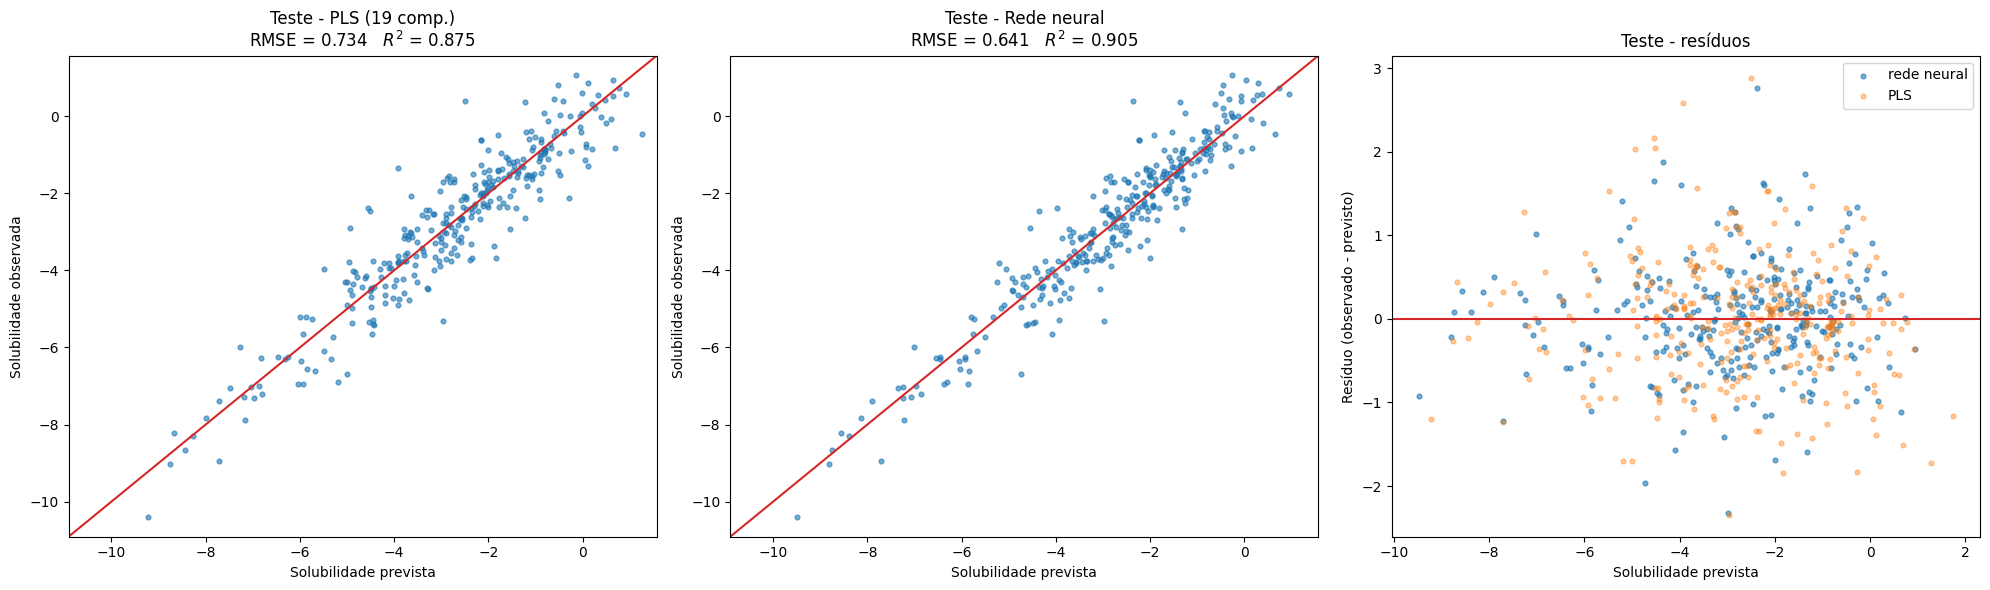

In [42]:
limites = [min(y_te.min(), y_previsto_teste_rn.min()) - 0.5, max(y_te.max(), y_previsto_teste_rn.max()) + 0.5]
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, previsto, nome in [(axes[0], y_previsto_teste, 'PLS (%d comp.)' % A_otimo),
                           (axes[1], y_previsto_teste_rn, 'Rede neural')]:
    ax.scatter(previsto, y_te, s=12, alpha=0.6)
    ax.plot(limites, limites, color='tab:red', lw=1.5)
    ax.set_xlim(limites)
    ax.set_ylim(limites)
    ax.set_xlabel('Solubilidade prevista')
    ax.set_ylabel('Solubilidade observada')
    ax.set_title('Teste - %s\nRMSE = %.3f   $R^2$ = %.3f' % (nome, rmse(y_te, previsto), r2(y_te, previsto)))

axes[2].scatter(y_previsto_teste_rn, y_te - y_previsto_teste_rn, s=12, alpha=0.6, label='rede neural')
axes[2].scatter(y_previsto_teste, y_te - y_previsto_teste, s=12, alpha=0.4, label='PLS')
axes[2].axhline(0, color='tab:red', lw=1.5)
axes[2].set_xlabel('Solubilidade prevista')
axes[2].set_ylabel('Resíduo (observado - previsto)')
axes[2].set_title('Teste - resíduos')
axes[2].legend()

plt.tight_layout()
salvar_figura('rn_teste')
plt.show()

## Discussão: o modelo não linear supera o linear?

**Melhores hiperparâmetros.** A validação cruzada escolheu uma rede com **uma camada oculta de 64
neurônios, *weight decay* 1,0, *dropout* 0,3 e 100 épocas** (RMSE de CV ≈ 0,629 ± 0,020). Algumas
observações sobre a busca:

- a arquitetura com 16 neurônios foi sistematicamente a pior (RMSE de CV entre 0,65 e 0,68): ela tem
  pouca capacidade para representar a relação;
- com 64 ou 128 neurônios os resultados ficam muito parecidos, e as 9 melhores configurações estão
  todas dentro de um erro padrão da melhor (0,629 a 0,637). A superfície de erro é achatada nessa região,
  e qualquer uma dessas escolhas daria um modelo equivalente;
- a regularização faz diferença: para todas as arquiteturas, *weight decay* maior e/ou *dropout*
  melhoraram o erro de CV. Isso é esperado com 951 compostos para 228 preditores, em que uma rede sem
  regularização decora o treino. Como o melhor *weight decay* ficou no extremo da grade (1,0), valores
  ainda maiores poderiam ser testados, mas a curva já está bem achatada;
- a camada extra, (64, 32), não ajudou: a rede mais funda ficou um pouco pior que a de uma camada só.

**Desempenho no teste.** O *ensemble* de 5 redes obteve **RMSE ≈ 0,641 e $R^2$ ≈ 0,905** no conjunto
de teste. O PLS tinha obtido RMSE ≈ 0,734 e $R^2$ ≈ 0,875. A rede reduz o RMSE em cerca de 0,09
(13%) e passa a explicar 90% da variância da solubilidade em vez de 87,5%. Isso também é consistente com
a CV: o RMSE de CV da rede (0,63) já era menor que o do PLS (0,71), e o de teste ficou próximo dele.
Mesmo as redes individuais, sem *ensemble*, foram todas melhores que o PLS (RMSE entre 0,64 e 0,69).

O *bootstrap* pareado confirma que a diferença não é sorte da amostra de teste: o intervalo de
confiança de 95% para $\text{RMSE}_{\text{PLS}} - \text{RMSE}_{\text{rede}}$ é aproximadamente
[0,05; 0,14] e não contém o zero, e a rede foi melhor em todas as 5000 reamostras. Nos gráficos, a nuvem
observado x previsto da rede é visivelmente mais estreita em torno da diagonal, e os resíduos dela são
menores que os do PLS em praticamente toda a faixa de solubilidade.

Um ponto de atenção é o erro de treino da rede (RMSE ≈ 0,26), bem menor que o de teste. Ela se ajusta
muito mais ao treino que o PLS, mas como a escolha dos hiperparâmetros foi feita por CV, essa
flexibilidade foi controlada e se traduziu em melhor generalização, não em sobreajuste.

**O que isso diz sobre a relação entre preditores e saída?** Sim, o modelo não linear supera o linear.
Isso indica que **a relação entre os preditores e a solubilidade não é puramente linear**, mesmo depois
da transformação dos preditores. Existe uma parte da estrutura que uma combinação linear dos 228
preditores (que é tudo o que o PLS consegue representar, por mais componentes que use) não captura. As
possíveis fontes dessa não linearidade são:

- **curvatura nas relações individuais**, que já tinha aparecido na análise exploratória: preditores
  como `NumAromaticBonds`, `NumMultBonds`, `SurfaceArea1/2`, `NumOxygen` e `NumHydrogen` têm uma relação
  curva (e às vezes não monotônica) com a solubilidade. A rede consegue modelar essas formas; o PLS só
  consegue ajustar uma reta para cada uma;
- **interações entre preditores**: o efeito de um descritor pode depender do valor de outro. Por
  exemplo, o efeito de ter mais oxigênios (mais polaridade, mais solubilidade) deve depender do tamanho
  da molécula, já que numa molécula grande e aromática um grupo polar pesa menos. Um modelo linear soma
  os efeitos de forma independente, enquanto as unidades ocultas da rede combinam vários preditores
  antes da não linearidade e conseguem representar esse tipo de interação.

Por outro lado, o ganho é moderado (de 87,5% para 90% da variância explicada), e o PLS já captura a
maior parte do sinal. A leitura mais justa é que a relação é **predominantemente linear**, dominada pelo
tamanho da molécula (que entra de forma quase linear após a transformação, como visto no item 0), com
uma **componente não linear secundária, mas real**, que a rede neural aproveita. A rede ganha em
precisão, mas perde em interpretabilidade: no PLS dá para ler os coeficientes de cada preditor, enquanto
na rede essa leitura direta não existe.
